## Calculation

Contains the `CALCULATION` notebook section.


In [ ]:
# CALCULATION
%matplotlib inline

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import importlib

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving = phase_velocity.solve_front_energy_conserving
solve_front_adiabatic = phase_velocity.solve_front_adiabatic
_quark_thermo_state = phase_velocity._quark_thermo_state

# Tunable physical parameters.
n0 = 0.16 * const.MeV_fm**3
T = 10
nB_N = 3.0 * n0
B = 180.0
aQstar = 0.3

# Tunable solver parameters.
ms = 0.0
NM_type = 'PNM'
param = para.paraQMCRMF3
tail_eps = 1.0e-5
n_mesh = 40
tol_bvp = 1.0e-4
max_nodes = 1200
jB_guess = None
TQ_guess = 60
jB_bounds = (1.0e-5, 5.0)

common_solver_kwargs = dict(
    T=T,
    nB_N=nB_N,
    B_one_forth=B,
    aQstar=aQstar,
    ms=ms,
    param=param,
    NM_type=NM_type,
    tail_eps=tail_eps,
    n_mesh=n_mesh,
    tol_bvp=tol_bvp,
    max_nodes=max_nodes,
    jB_guess=jB_guess,
    TQ_guess=TQ_guess,
    jB_bounds=jB_bounds,
    return_profile=True,
    verb=False,
)

res_energy = solve_front_energy_conserving(**common_solver_kwargs)
res_adiabatic = solve_front_adiabatic(
    **common_solver_kwargs,
    interface_temperature_mode='hu_const',
)

solver_results = {
    'energy_conserving': res_energy,
    'adiabatic_hu_const': res_adiabatic,
}


def _raise_solver_failure(label, result):
    seed = result.get('continuation_seed_aQstar', None)
    seed_note = '' if seed is None else f'\n  continuation seed aQstar = {seed:g} (internal staged solve, not the requested target)'
    raise RuntimeError(
        f'{label} solve failed for requested aQstar={aQstar:g}, T_N={T:g} MeV.'
        f'{seed_note}\n  message: {result.get("message", "")}'
    )


for label, result in solver_results.items():
    if not bool(result.get('success')):
        _raise_solver_failure(label, result)

if res_energy.get('energy_flux_equation') != 'E_rgamma_const':
    raise RuntimeError(
        'energy solver returned unexpected energy_flux_equation: '
        + repr(res_energy.get('energy_flux_equation'))
    )

if res_energy.get('_root_method') != 'solve_bvp_parameter_2d':
    raise RuntimeError(
        'energy solver should use the two-parameter BVP after deriving E upstream; got '
        + repr(res_energy.get('_root_method'))
    )
if 'E_left_residual' in res_energy:
    raise RuntimeError('energy solver should not expose E_left_residual after the two-parameter refactor')

required_energy_profile_keys = [
    'E', 'E_N', 'E_Q', 'E_Qstar', 'r_gamma_N', 'r_gamma_Q', 'r_gamma_Qstar',
    'x', 'a', 'q', 'u', 'nB', 'muB', 'muK', 'T_profile', 'h_profile',
    'r_gamma_profile', 'D_profile', 'eta_profile', 'gamma_profile',
]
missing_energy_keys = [key for key in required_energy_profile_keys if key not in res_energy]
if missing_energy_keys:
    raise RuntimeError('energy solver result missing profile keys: ' + ', '.join(missing_energy_keys))

required_adiabatic_profile_keys = ['x', 'a', 'q', 'w', 'u', 'nB', 'muB', 'muK', 'T_profile', 's_profile']
missing_adiabatic_keys = [key for key in required_adiabatic_profile_keys if key not in res_adiabatic]
if missing_adiabatic_keys:
    raise RuntimeError('adiabatic solver result missing profile keys: ' + ', '.join(missing_adiabatic_keys))

T_energy = np.asarray(res_energy['T_profile'], dtype=float)
if not np.all(np.isfinite(T_energy)) or np.any(T_energy <= 0.0):
    raise RuntimeError('energy solver returned a non-finite or non-positive T_profile')
if np.ptp(T_energy) <= 1.0e-6 * max(1.0, abs(float(np.mean(T_energy)))):
    raise RuntimeError('energy solver T_profile is effectively constant')

E_energy = (
    np.asarray(res_energy['h_profile'], dtype=float)
    * np.asarray(res_energy['u'], dtype=float)
    * np.asarray(res_energy['r_gamma_profile'], dtype=float)
)
E_scale = max(abs(float(res_energy['E'])), 1.0)
E_variation_norm = float(np.ptp(E_energy) / E_scale)
E_match_norm = float(np.max(np.abs(E_energy - float(res_energy['E']))) / E_scale)
if E_variation_norm > 1.0e-6 or E_match_norm > 1.0e-6:
    raise RuntimeError(
        f'energy solver reconstructed h*u is not constant enough: '
        f'variation={E_variation_norm:.3e}, match={E_match_norm:.3e}'
    )

T_adiabatic = np.asarray(res_adiabatic['T_profile'], dtype=float)
w_adiabatic = np.asarray(res_adiabatic['w'], dtype=float)
s_adiabatic = np.asarray(res_adiabatic['s_profile'], dtype=float)
if not np.all(np.isfinite(T_adiabatic)) or np.any(T_adiabatic <= 0.0):
    raise RuntimeError('adiabatic solver returned a non-finite or non-positive T_profile')
if not np.all(np.isfinite(w_adiabatic)) or not np.all(np.isfinite(s_adiabatic)):
    raise RuntimeError('adiabatic solver returned non-finite w or s_profile values')


def _profile_enthalpy(result):
    if 'h_profile' in result:
        return np.asarray(result['h_profile'], dtype=float)

    muB_values = np.asarray(result['muB'], dtype=float)
    muK_values = np.asarray(result['muK'], dtype=float)
    T_values = np.asarray(result['T_profile'], dtype=float)
    jB_value = float(result['jB'])
    h_values = np.empty_like(muB_values)
    for i, (muB_value, muK_value, T_value) in enumerate(zip(muB_values, muK_values, T_values)):
        h_values[i] = _quark_thermo_state(
            float(muB_value),
            float(muK_value),
            B,
            float(T_value),
            jB_value,
            ms=ms,
        )['h']
    return h_values


def _build_profile(label, result, color):
    x_nm = np.asarray(result['x'], dtype=float) * const.MeV_fm / 1.0e6
    u_values = np.asarray(result['u'], dtype=float)
    nB_values = np.asarray(result['nB'], dtype=float)
    h_values = _profile_enthalpy(result)
    return {
        'label': label,
        'result': result,
        'color': color,
        'x_nm': x_nm,
        'a': np.asarray(result['a'], dtype=float),
        'q': np.asarray(result['q'], dtype=float),
        'u_m_per_s': u_values * const.m_per_sec,
        'T': np.asarray(result['T_profile'], dtype=float),
        'muB': np.asarray(result['muB'], dtype=float),
        'muK': np.asarray(result['muK'], dtype=float),
        'nB_over_n0': nB_values / n0,
        'h': h_values,
        'r_gamma': np.sqrt(1.0 + u_values * u_values),
        'E_reconstructed': h_values * u_values * np.sqrt(1.0 + u_values * u_values),
        'h_over_nB': h_values / nB_values,
    }

profiles = {
    'energy_conserving': _build_profile('energy conserving', res_energy, 'C3'),
    'adiabatic_hu_const': _build_profile('adiabatic hu_const', res_adiabatic, 'C0'),
}

rows = []
for label, result in solver_results.items():
    rows.append({
        'solver': label,
        'success': bool(result.get('success')),
        'jB': result.get('jB', np.nan),
        'u_N_m_per_s': result.get('u_N', np.nan) * const.m_per_sec,
        'u_Q_m_per_s': result.get('u_Q', np.nan) * const.m_per_sec,
        'T_Q_MeV': result.get('T_Q', np.nan),
        'T_Qstar_MeV': result.get('T_Qstar', np.nan),
        'tail_norm': result.get('tail_residual_norm', np.nan),
        'E_right_norm': result.get('E_right_residual_norm', np.nan),
        'entropy_tail_norm': result.get('entropy_tail_residual_norm', np.nan),
        'E': result.get('E', np.nan),
        'E_N': result.get('E_N', np.nan),
        'E_Q': result.get('E_Q', np.nan),
        'E_Qstar': result.get('E_Qstar', np.nan),
        'r_gamma_N': result.get('r_gamma_N', np.nan),
        'r_gamma_Q': result.get('r_gamma_Q', np.nan),
        'r_gamma_Qstar': result.get('r_gamma_Qstar', np.nan),
        'h_over_nB_jump_residual': result.get('h_over_nB_jump_residual', np.nan),
        'bvp_nodes': result.get('bvp_nodes', np.nan),
        'message': result.get('message', ''),
    })

diagnostic_table = pd.DataFrame(rows)

print('Smoke tests passed.')
print(f'T_N = {T:g} MeV, nB_N = {nB_N / n0:g} n0, B^(1/4) = {B:g} MeV, aQstar = {aQstar:g}')
for label, result in solver_results.items():
    print(
        f"{label}: jB={result.get('jB', np.nan):.8g}, "
        f"u_N={result.get('u_N', np.nan) * const.m_per_sec:.8g} m/s, "
        f"T_Q={result.get('T_Q', np.nan):.8g} MeV, "
        f"T_Qstar={result.get('T_Qstar', np.nan):.8g} MeV"
    )

display(diagnostic_table)


## Visualization

Contains the `VISUALIZATION` notebook section.


In [ ]:
# VISUALIZATION
# FORCED_UPDATE_2026_05_04: screenshot-style 4x2 comparison plot.

import numpy as np
import matplotlib.pyplot as plt

# Tunable visualization parameters.
TitleFont = 20
LabelFont = 16
TickFont = 15
LegendFont = 14
LineWidth = 1.1
UpstreamLineWidth = 2.2
ReferenceLineWidth = 0.8
ProfileFigsize = (12, 11)
x_min_nm = -50.0
x_max_nm = 800.0
upstream_points = 120
show_diagnostic_table = False

energy_color = 'C0'
adiabatic_color = 'red'
energy_label = 'energy conserving'
adiabatic_label = 'adiabatic [hu]=0'

if show_diagnostic_table:
    display(diagnostic_table)

plot_modes = [
    (energy_label, profiles['energy_conserving'], res_energy, energy_color),
    (adiabatic_label, profiles['adiabatic_hu_const'], res_adiabatic, adiabatic_color),
]

x_left_nm = np.linspace(float(x_min_nm), 0.0, int(upstream_points))
P_N_plot = float(phase_velocity.PNM_n(nB_N, T, param=param, NM_type=NM_type))
e_N_plot = float(phase_velocity.edensNM_n(nB_N, T, param=param))
h_N_plot = P_N_plot + e_N_plot
nB_N_over_n0_plot = float(nB_N / n0)

try:
    muB_N_plot = float(
        phase_velocity._solve_scalar_root(
            lambda muB: phase_velocity.nB_NM(muB, T) - nB_N,
            1050.0,
        )
    )
except Exception:
    muB_N_plot = np.nan


def _sorted_profile(profile):
    order = np.argsort(np.asarray(profile['x_nm'], dtype=float))
    out = {}
    for key, value in profile.items():
        if isinstance(value, np.ndarray) and value.shape == order.shape:
            out[key] = value[order]
        else:
            out[key] = value
    return out


def _plot_downstream(ax, profile, key, color, label):
    prof = _sorted_profile(profile)
    x_vals = np.asarray(prof['x_nm'], dtype=float)
    y_vals = np.asarray(prof[key], dtype=float)
    mask = np.isfinite(x_vals) & np.isfinite(y_vals) & (x_vals <= x_max_nm)
    ax.plot(x_vals[mask], y_vals[mask], lw=LineWidth, color=color, label=label)


def _left_value(result, key):
    u_N = float(result.get('u_N', np.nan))
    if key == 'a':
        return float(result.get('a_N', np.nan))
    if key == 'u_m_per_s':
        return u_N * const.m_per_sec
    if key == 'nB_over_n0':
        return nB_N_over_n0_plot
    if key == 'muK':
        return float(result.get('muK_N', 0.0))
    if key == 'muB':
        return muB_N_plot
    if key == 'T':
        return float(T)
    if key == 'h':
        return h_N_plot
    if key == 'hu':
        return h_N_plot * u_N
    raise KeyError(key)


def _plot_upstream(ax, result, key, color):
    y_left = _left_value(result, key)
    if np.isfinite(y_left):
        ax.plot(
            x_left_nm,
            np.full_like(x_left_nm, y_left),
            lw=UpstreamLineWidth,
            ls='--',
            color=color,
            alpha=0.80,
        )


def _style_axis(ax):
    ax.axvline(0.0, color='0.25', lw=ReferenceLineWidth)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.set_xlim(x_min_nm, x_max_nm)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)

fig, axes = plt.subplots(4, 2, figsize=ProfileFigsize, sharex=True, constrained_layout=True)
axes = axes.ravel()

panel_specs = [
    ('a', r'$a(x)$', (0.0, 0.7), None, 'upper left'),
    ('u_m_per_s', r'$u(x)$ [m/s]', (0.0, 50.0), None, 'upper right'),
    ('nB_over_n0', r'$n_B(x)/n_0$', (0.0, 4.8), 'x < 0: upstream $n_N/n_0$', 'center'),
    ('muK', r'$\mu_K(x)$ [MeV]', (0.0, 80.0), None, 'upper right'),
    ('muB', r'$\mu_B(x)$ [MeV]', (0.0, 1250.0), r'x < 0: upstream $\mu_B$', 'center'),
    ('T', r'$T(x)$ [MeV]', (0.0, 35.0), 'x < 0: upstream $T$', 'center'),
    ('h', r'$h(x)$ [MeV$^4$]', None, None, 'center'),
    ('hu', r'$h(x)u(x)$ [MeV$^4$]', None, None, 'center'),
]

for ax, (key, ylabel, ylim, upstream_label, legend_loc) in zip(axes, panel_specs):
    for label, profile, result, color in plot_modes:
        if key == 'hu':
            profile = dict(profile)
            profile['hu'] = np.asarray(profile['h'], dtype=float) * np.asarray(result['u'], dtype=float)
        _plot_downstream(ax, profile, key, color, label)
        _plot_upstream(ax, result, key, color)

    if upstream_label is not None:
        if key == 'nB_over_n0':
            y_ref = nB_N_over_n0_plot
        elif key == 'muB':
            y_ref = muB_N_plot
        elif key == 'T':
            y_ref = float(T)
        else:
            y_ref = np.nan
        if np.isfinite(y_ref):
            ax.axhline(y_ref, color='0.45', lw=ReferenceLineWidth, ls='--', label=upstream_label)

    if key == 'T':
        ax.plot([0.0], [float(T)], marker='o', ms=3.0, color=energy_color)
        ax.plot([0.0], [float(res_energy['T_Qstar'])], marker='o', ms=3.0, color=energy_color)
        ax.axhline(float(res_energy['T_Q']), color=energy_color, lw=ReferenceLineWidth, ls=':', alpha=0.8, label=fr'{energy_label} $T_Q={float(res_energy["T_Q"]):.2f}$ MeV')
        ax.axhline(float(res_adiabatic['T_Q']), color=adiabatic_color, lw=ReferenceLineWidth, ls=':', alpha=0.8, label=fr'{adiabatic_label} $T_Q={float(res_adiabatic["T_Q"]):.2f}$ MeV')

    _style_axis(ax)
    ax.set_ylabel(ylabel, fontsize=LabelFont)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.legend(fontsize=LegendFont, loc=legend_loc, framealpha=0.90)

for ax in axes[-2:]:
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

fig.suptitle(
    rf'Energy-Conserving Interface Comparison: $T_N={float(T):.2f}$ MeV, '
    rf'$n_B^N={float(nB_N / n0):.1f} n_0$, $a_{{Q\star}}={float(aQstar):.3f}$',
    fontsize=TitleFont,
)

plt.savefig("energy_converving_vs_adiabatic[hu]=0.pdf", bbox_inches='tight', dpi=300)

plt.show()

print(f"energy conserving T_Q = {float(res_energy['T_Q']):.6g} MeV, T_Qstar = {float(res_energy['T_Qstar']):.6g} MeV")
print(f"adiabatic [hu]=0 T_Q = {float(res_adiabatic['T_Q']):.6g} MeV, T_Qstar = {float(res_adiabatic['T_Qstar']):.6g} MeV")


## Timing Comparison

Contains the `TIMING_COMPARISON` notebook section.


In [ ]:
# TIMING_COMPARISON
import time

# Tunable timing parameters.
timing_repeats = 3
timing_warmup_repeats = 0
timing_return_profile = True
timing_solver_order = ('adiabatic_hu_const', 'energy_conserving')
timing_verbose = False

# Use the exact same physical/numerical inputs from the calculation cell.
timing_common_kwargs = dict(common_solver_kwargs)
timing_common_kwargs['return_profile'] = bool(timing_return_profile)
timing_common_kwargs['verb'] = bool(timing_verbose)


def _run_timed_solver(label):
    if label == 'energy_conserving':
        return solve_front_energy_conserving(**timing_common_kwargs)
    if label == 'adiabatic_hu_const':
        return solve_front_adiabatic(
            **timing_common_kwargs,
            interface_temperature_mode='hu_const',
        )
    raise ValueError(f'unknown timing solver label: {label!r}')


for _ in range(int(timing_warmup_repeats)):
    for label in timing_solver_order:
        warmup_result = _run_timed_solver(label)
        if not bool(warmup_result.get('success')):
            raise RuntimeError(f'warmup {label} solve failed: {warmup_result.get("message", "")}')

timing_rows = []
for repeat in range(int(timing_repeats)):
    for label in timing_solver_order:
        t0 = time.perf_counter()
        result = _run_timed_solver(label)
        elapsed_s = time.perf_counter() - t0
        timing_rows.append({
            'solver': label,
            'repeat': repeat + 1,
            'elapsed_s': elapsed_s,
            'success': bool(result.get('success')),
            'jB': result.get('jB', np.nan),
            'T_Q': result.get('T_Q', np.nan),
            'T_Qstar': result.get('T_Qstar', np.nan),
            'bvp_nodes': result.get('bvp_nodes', np.nan),
            'bvp_niter': result.get('bvp_niter', np.nan),
            'bvp_ode_calls': result.get('bvp_ode_calls', np.nan),
            'local_state_calls': result.get('local_state_calls', np.nan),
            'profile_state_calls': result.get('profile_state_calls', np.nan),
            'energy_flux_equation': result.get('energy_flux_equation', ''),
            'interface_temperature_mode': result.get('interface_temperature_mode', ''),
            'message': result.get('message', ''),
        })
        if not bool(result.get('success')):
            raise RuntimeError(f'timed {label} solve failed: {result.get("message", "")}')

timing_df = pd.DataFrame(timing_rows)
timing_summary = (
    timing_df
    .groupby('solver', as_index=False)
    .agg(
        repeats=('elapsed_s', 'size'),
        mean_s=('elapsed_s', 'mean'),
        median_s=('elapsed_s', 'median'),
        std_s=('elapsed_s', 'std'),
        min_s=('elapsed_s', 'min'),
        max_s=('elapsed_s', 'max'),
        all_success=('success', 'all'),
        mean_bvp_nodes=('bvp_nodes', 'mean'),
        mean_bvp_niter=('bvp_niter', 'mean'),
        mean_local_state_calls=('local_state_calls', 'mean'),
        mean_profile_state_calls=('profile_state_calls', 'mean'),
    )
)

baseline_solver = timing_solver_order[0]
baseline_median = float(timing_summary.loc[timing_summary['solver'] == baseline_solver, 'median_s'].iloc[0])
timing_summary['median_vs_' + baseline_solver] = timing_summary['median_s'] / baseline_median

display(timing_df)
display(timing_summary)


## Timing Visualization

Contains the `TIMING_VISUALIZATION` notebook section.


In [ ]:
# TIMING_VISUALIZATION
# Tunable timing visualization parameters.
TimingTitleFont = 15
TimingLabelFont = 12
TimingTickFont = 11
TimingLegendFont = 11
TimingFigsize = (8.0, 4.8)
TimingScatterFigsize = (8.0, 4.8)
TimingBarColor = {'adiabatic_hu_const': 'C0', 'energy_conserving': 'C3'}
TimingBarAlpha = 0.82
TimingPointSize = 60
show_timing_grid = True
show_timing_values = True

if 'timing_df' not in globals() or 'timing_summary' not in globals():
    raise RuntimeError('Run the TIMING_COMPARISON cell first.')

plot_summary = timing_summary.copy().sort_values('median_s')
colors = [TimingBarColor.get(label, '0.5') for label in plot_summary['solver']]

fig, ax = plt.subplots(figsize=TimingFigsize, constrained_layout=True)
bars = ax.bar(
    plot_summary['solver'],
    plot_summary['median_s'],
    color=colors,
    alpha=TimingBarAlpha,
    label='median runtime',
)

for idx, row in plot_summary.reset_index(drop=True).iterrows():
    yerr_low = max(float(row['median_s'] - row['min_s']), 0.0)
    yerr_high = max(float(row['max_s'] - row['median_s']), 0.0)
    ax.errorbar(
        idx,
        row['median_s'],
        yerr=[[yerr_low], [yerr_high]],
        color='black',
        capsize=5,
        lw=1.2,
    )
    if show_timing_values:
        ax.text(
            idx,
            row['median_s'],
            f"{row['median_s']:.3g}s",
            ha='center',
            va='bottom',
            fontsize=TimingTickFont,
        )

ax.set_title('Solver Runtime Comparison', fontsize=TimingTitleFont)
ax.set_ylabel('median elapsed time [s]', fontsize=TimingLabelFont)
ax.tick_params(axis='x', labelrotation=15, labelsize=TimingTickFont)
ax.tick_params(axis='y', labelsize=TimingTickFont)
if show_timing_grid:
    ax.grid(axis='y', alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=TimingScatterFigsize, constrained_layout=True)
for idx, solver in enumerate(timing_solver_order):
    sub = timing_df[timing_df['solver'] == solver]
    ax.scatter(
        np.full(len(sub), idx),
        sub['elapsed_s'],
        s=TimingPointSize,
        color=TimingBarColor.get(solver, '0.5'),
        label=solver,
        alpha=0.85,
    )
    ax.plot(
        [idx - 0.18, idx + 0.18],
        [float(sub['elapsed_s'].median()), float(sub['elapsed_s'].median())],
        color='black',
        lw=1.8,
    )
ax.set_xticks(range(len(timing_solver_order)))
ax.set_xticklabels(timing_solver_order, rotation=15, ha='right')
ax.set_title('Per-Repeat Runtime Samples', fontsize=TimingTitleFont)
ax.set_ylabel('elapsed time [s]', fontsize=TimingLabelFont)
ax.tick_params(labelsize=TimingTickFont)
if show_timing_grid:
    ax.grid(axis='y', alpha=0.25)
plt.show()

display(timing_summary)


## aQstar Upper Bound Energy Calc

Contains the `A_QSTAR_UPPER_BOUND_ENERGY_CALC` notebook section.


In [ ]:
# A_QSTAR_UPPER_BOUND_ENERGY_CALC
# Adaptive profile-seeded continuation scan for the energy-conserving solver.

import importlib

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving = phase_velocity.solve_front_energy_conserving
_solve_front_energy_conserving_once = phase_velocity._solve_front_energy_conserving_once
PNM_n = phase_velocity.PNM_n
edensNM_n = phase_velocity.edensNM_n
_solve_muB_Q_at_muK0_for_given_Pi_ms = phase_velocity._solve_muB_Q_at_muK0_for_given_Pi_ms
_solve_local_quark_state_from_a_E_and_Pi = phase_velocity._solve_local_quark_state_from_a_E_and_Pi
_quark_thermo_state = phase_velocity._quark_thermo_state

# Self-contained physical inputs for this scan.
n0_energy_upper_bound_scan = 0.16 * const.MeV_fm**3
T_energy_upper_bound_scan = 0.1
nB_N_energy_upper_bound_scan = 3.0 * n0_energy_upper_bound_scan
B14_energy_upper_bound_scan = 180.0
ms_energy_upper_bound_scan = 0.0
NM_type_energy_upper_bound_scan = 'PNM'
param_energy_upper_bound_scan = para.paraQMCRMF3

# Tunable upper-bound search controls.
aQstar_energy_upper_bound_start = 0.30
aQstar_energy_upper_bound_max = 0.95
aQstar_energy_upper_bound_da_initial = 0.01
aQstar_energy_upper_bound_da_min = 1.0e-4
aQstar_energy_upper_bound_max_attempts = 100

# Tunable BVP guesses and controls.
jB_guess_energy_upper_bound_scan = None
TQ_guess_energy_upper_bound_scan = 60.0
jB_bounds_energy_upper_bound_scan = (1.0e-5, 5.0)
tail_eps_energy_upper_bound_scan = 1.0e-5
n_mesh_energy_upper_bound_scan = 40
tol_energy_upper_bound_scan = 1.0e-4
max_nodes_energy_upper_bound_scan = 1200

energy_upper_bound_common_kwargs = dict(
    T=T_energy_upper_bound_scan,
    nB_N=nB_N_energy_upper_bound_scan,
    B_one_forth=B14_energy_upper_bound_scan,
    ms=ms_energy_upper_bound_scan,
    param=param_energy_upper_bound_scan,
    NM_type=NM_type_energy_upper_bound_scan,
    tail_eps=tail_eps_energy_upper_bound_scan,
    n_mesh=n_mesh_energy_upper_bound_scan,
    tol_bvp=tol_energy_upper_bound_scan,
    max_nodes=max_nodes_energy_upper_bound_scan,
    jB_bounds=jB_bounds_energy_upper_bound_scan,
    verb=False,
)


def _energy_upper_as_float(value):
    try:
        return float(value)
    except Exception:
        return np.nan


def _energy_upper_clip_jB_guess(jB_value):
    jB_value = _energy_upper_as_float(jB_value)
    if not np.isfinite(jB_value) or jB_value <= 0.0:
        return np.nan
    if jB_bounds_energy_upper_bound_scan is None:
        return jB_value
    lower, upper = map(float, jB_bounds_energy_upper_bound_scan)
    return float(np.clip(jB_value, lower * (1.0 + 1.0e-6), upper * (1.0 - 1.0e-6)))


def _energy_upper_trial_seed_from_history(history, target_a):
    if not history:
        return _energy_upper_clip_jB_guess(jB_guess_energy_upper_bound_scan), _energy_upper_as_float(TQ_guess_energy_upper_bound_scan)

    last = history[-1]
    jB_trial = _energy_upper_as_float(last.get('jB'))
    TQ_trial = _energy_upper_as_float(last.get('T_Q'))
    if len(history) >= 2:
        prev = history[-2]
        da_prev = _energy_upper_as_float(last.get('aQstar')) - _energy_upper_as_float(prev.get('aQstar'))
        da_next = float(target_a) - _energy_upper_as_float(last.get('aQstar'))
        if np.isfinite(da_prev) and abs(da_prev) > 0.0 and np.isfinite(da_next):
            jB_trial = jB_trial + (_energy_upper_as_float(last.get('jB')) - _energy_upper_as_float(prev.get('jB'))) / da_prev * da_next
            TQ_trial = TQ_trial + (_energy_upper_as_float(last.get('T_Q')) - _energy_upper_as_float(prev.get('T_Q'))) / da_prev * da_next

    return _energy_upper_clip_jB_guess(jB_trial), max(_energy_upper_as_float(TQ_trial), 1.0e-8)


def _energy_upper_algebraic_qstar_check(aQstar_value, jB_trial, TQ_trial):
    jB_trial = _energy_upper_clip_jB_guess(jB_trial)
    TQ_trial = _energy_upper_as_float(TQ_trial)
    if (not np.isfinite(jB_trial)) or jB_trial <= 0.0 or (not np.isfinite(TQ_trial)) or TQ_trial <= 0.0:
        return {
            'algebraic_ok': False,
            'failure_label': 'unknown/inconclusive',
            'algebraic_message': 'No finite positive trial jB/T_Q was available for the algebraic check.',
            'algebraic_a_N': np.nan,
            'algebraic_T_Qstar': np.nan,
            'algebraic_E_right_residual_norm': np.nan,
            'algebraic_E_Qstar_residual_norm': np.nan,
        }

    try:
        P_N = float(PNM_n(
            nB_N_energy_upper_bound_scan,
            T_energy_upper_bound_scan,
            param=param_energy_upper_bound_scan,
            NM_type=NM_type_energy_upper_bound_scan,
        ))
        e_N = float(edensNM_n(nB_N_energy_upper_bound_scan, T_energy_upper_bound_scan, param=param_energy_upper_bound_scan))
        h_N = P_N + e_N
        u_N = jB_trial / nB_N_energy_upper_bound_scan
        r_gamma_N = np.sqrt(1.0 + u_N * u_N)
        Pi = h_N * u_N * u_N + P_N
        E = h_N * u_N * r_gamma_N

        muB_Q = _solve_muB_Q_at_muK0_for_given_Pi_ms(
            Pi,
            jB_trial,
            B14_energy_upper_bound_scan,
            TQ_trial,
            ms=ms_energy_upper_bound_scan,
            initial_guess=1200.0,
        )
        thermo_Q = _quark_thermo_state(muB_Q, 0.0, B14_energy_upper_bound_scan, TQ_trial, jB_trial, ms=ms_energy_upper_bound_scan)
        nB_Q = float(thermo_Q['nB'])
        nK_Q = 0.0 if abs(ms_energy_upper_bound_scan) <= 1.0e-12 else float(thermo_Q['nK'])
        u_Q = float(thermo_Q['u'])
        E_Q = float(thermo_Q['h'] * u_Q * np.sqrt(1.0 + u_Q * u_Q))
        muK_seed = max(20.0, 250.0 * abs(float(aQstar_value)))

        thermo_Qstar = _solve_local_quark_state_from_a_E_and_Pi(
            aQstar_value,
            E,
            Pi,
            jB_trial,
            nB_Q,
            nK_Q,
            B14_energy_upper_bound_scan,
            ms=ms_energy_upper_bound_scan,
            initial_guess=(muB_Q, muK_seed, TQ_trial),
            T_ref=TQ_trial,
        )
        u_Qstar = float(thermo_Qstar['u'])
        E_Qstar = float(thermo_Qstar['h'] * u_Qstar * np.sqrt(1.0 + u_Qstar * u_Qstar))
        E_scale = max(abs(E), abs(E_Q), abs(E_Qstar), np.finfo(float).tiny)

        return {
            'algebraic_ok': True,
            'failure_label': 'BVP/local closure failure',
            'algebraic_message': 'Endpoint and Qstar algebraic energy states exist at the extrapolated trial point.',
            'algebraic_a_N': float((nB_N_energy_upper_bound_scan - nK_Q) / nB_Q),
            'algebraic_T_Qstar': float(thermo_Qstar['T']),
            'algebraic_E_right_residual_norm': float((E_Q - E) / E_scale),
            'algebraic_E_Qstar_residual_norm': float((E_Qstar - E) / E_scale),
        }
    except Exception as exc:
        return {
            'algebraic_ok': False,
            'failure_label': 'algebraic thermodynamic failure',
            'algebraic_message': str(exc),
            'algebraic_a_N': np.nan,
            'algebraic_T_Qstar': np.nan,
            'algebraic_E_right_residual_norm': np.nan,
            'algebraic_E_Qstar_residual_norm': np.nan,
        }


def _energy_upper_result_row(aQstar_value, result, attempt_kind, jB_trial=np.nan, TQ_trial=np.nan, algebraic=None):
    algebraic = algebraic or {}
    u_N = _energy_upper_as_float(result.get('u_N', np.nan))
    jB_value = _energy_upper_as_float(result.get('jB', np.nan))
    TQ_value = _energy_upper_as_float(result.get('T_Q', np.nan))
    a_N = _energy_upper_as_float(result.get('a_N', np.nan))
    u_N_trial = _energy_upper_as_float(jB_trial) / nB_N_energy_upper_bound_scan if np.isfinite(_energy_upper_as_float(jB_trial)) else np.nan
    return {
        'mode': 'E_rgamma_const',
        'aQstar': float(aQstar_value),
        'success': bool(result.get('success')),
        'attempt_kind': attempt_kind,
        'jB': jB_value,
        'u_N': u_N,
        'u_N_m_s': u_N * const.m_per_sec if np.isfinite(u_N) else np.nan,
        'T_Q': TQ_value,
        'T_Qstar': _energy_upper_as_float(result.get('T_Qstar', np.nan)),
        'a_N': a_N,
        'a_N_minus_aQstar': a_N - float(aQstar_value) if np.isfinite(a_N) else np.nan,
        'E': _energy_upper_as_float(result.get('E', np.nan)),
        'E_right_residual_norm': _energy_upper_as_float(result.get('E_right_residual_norm', np.nan)),
        'bvp_nodes': _energy_upper_as_float(result.get('bvp_nodes', np.nan)),
        'local_state_failures': _energy_upper_as_float(result.get('local_state_failures', np.nan)),
        'global_state_failures': _energy_upper_as_float(result.get('global_state_failures', np.nan)),
        'root_method': result.get('_root_method', ''),
        'message': str(result.get('message', '')),
        'jB_trial': _energy_upper_as_float(jB_trial),
        'T_Q_trial': _energy_upper_as_float(TQ_trial),
        'u_N_trial_m_s': u_N_trial * const.m_per_sec if np.isfinite(u_N_trial) else np.nan,
        'u_N_plot_m_s': u_N * const.m_per_sec if np.isfinite(u_N) else (u_N_trial * const.m_per_sec if np.isfinite(u_N_trial) else np.nan),
        'algebraic_ok': bool(algebraic.get('algebraic_ok', False)) if not bool(result.get('success')) else True,
        'failure_label': 'success' if bool(result.get('success')) else algebraic.get('failure_label', 'unknown/inconclusive'),
        'algebraic_message': algebraic.get('algebraic_message', ''),
        'algebraic_a_N': _energy_upper_as_float(algebraic.get('algebraic_a_N', np.nan)),
        'algebraic_T_Qstar': _energy_upper_as_float(algebraic.get('algebraic_T_Qstar', np.nan)),
        'algebraic_E_right_residual_norm': _energy_upper_as_float(algebraic.get('algebraic_E_right_residual_norm', np.nan)),
        'algebraic_E_Qstar_residual_norm': _energy_upper_as_float(algebraic.get('algebraic_E_Qstar_residual_norm', np.nan)),
    }


aQstar_energy_upper_bound_attempts = []
aQstar_energy_upper_bound_success_profile = None

print('\n=== E_rgamma_const: adaptive aQstar continuation ===')
seed = solve_front_energy_conserving(
    **energy_upper_bound_common_kwargs,
    aQstar=aQstar_energy_upper_bound_start,
    jB_guess=jB_guess_energy_upper_bound_scan,
    TQ_guess=TQ_guess_energy_upper_bound_scan,
    return_profile=True,
)
seed_row = _energy_upper_result_row(aQstar_energy_upper_bound_start, seed, 'seed')
aQstar_energy_upper_bound_attempts.append(seed_row)
print(
    f"seed aQstar={aQstar_energy_upper_bound_start:.5f}: success={seed_row['success']}, "
    f"u_N={seed_row['u_N_m_s']:.6g} m/s, T_Q={seed_row['T_Q']:.6g}, "
    f"T_Qstar={seed_row['T_Qstar']:.6g}"
)

if seed_row['success']:
    current = seed
    current_a = float(aQstar_energy_upper_bound_start)
    da = float(aQstar_energy_upper_bound_da_initial)
    history = [seed_row]
    attempts = 0

    while current_a < aQstar_energy_upper_bound_max - 1.0e-12 and attempts < aQstar_energy_upper_bound_max_attempts:
        attempts += 1
        target_a = float(min(aQstar_energy_upper_bound_max, current_a + da))
        jB_trial, TQ_trial = _energy_upper_trial_seed_from_history(history, target_a)
        jB_initial = jB_trial if np.isfinite(jB_trial) and jB_trial > 0.0 else current.get('jB')
        TQ_initial = TQ_trial if np.isfinite(TQ_trial) and TQ_trial > 0.0 else current.get('T_Q')

        trial = _solve_front_energy_conserving_once(
            **energy_upper_bound_common_kwargs,
            aQstar=target_a,
            jB_guess=jB_initial,
            TQ_guess=TQ_initial,
            return_profile=True,
            profile_guess=current,
            seed_profile=True,
        )

        if bool(trial.get('success')):
            row = _energy_upper_result_row(target_a, trial, 'continuation_success')
            aQstar_energy_upper_bound_attempts.append(row)
            history.append(row)
            current = trial
            current_a = target_a
            da = min(float(aQstar_energy_upper_bound_da_initial), max(da, float(aQstar_energy_upper_bound_da_min)))
            print(
                f"aQstar={target_a:.5f}: success, u_N={row['u_N_m_s']:.6g} m/s, "
                f"T_Q={row['T_Q']:.6g}, T_Qstar={row['T_Qstar']:.6g}, "
                f"a_N-aQstar={row['a_N_minus_aQstar']:.6g}"
            )
        else:
            algebraic = _energy_upper_algebraic_qstar_check(target_a, jB_trial, TQ_trial)
            row = _energy_upper_result_row(target_a, trial, 'continuation_failure', jB_trial=jB_trial, TQ_trial=TQ_trial, algebraic=algebraic)
            aQstar_energy_upper_bound_attempts.append(row)
            print(
                f"aQstar={target_a:.5f}: failed, da={da:.3g}, "
                f"label={row['failure_label']}, trial_u_N={row['u_N_trial_m_s']:.6g} m/s"
            )
            da *= 0.5
            if da < aQstar_energy_upper_bound_da_min:
                print(f"  stopping E_rgamma_const: da={da:.3g} < da_min={aQstar_energy_upper_bound_da_min:.3g}")
                break

    aQstar_energy_upper_bound_success_profile = current
else:
    print(f"  seed failed: {seed_row['message'][:220]}")


aQstar_energy_upper_bound_df = pd.DataFrame(aQstar_energy_upper_bound_attempts)

energy_upper_summary_cols = [
    'mode', 'aQstar', 'success', 'u_N_m_s', 'T_Q', 'T_Qstar', 'a_N_minus_aQstar',
    'E_right_residual_norm', 'failure_label', 'algebraic_ok', 'local_state_failures',
    'global_state_failures', 'root_method',
]
print('\nAdaptive energy upper-bound scan summary:')
display(aQstar_energy_upper_bound_df[energy_upper_summary_cols])


## Visualize aQstar Upper Bound Energy

Contains the `VISUALIZE_A_QSTAR_UPPER_BOUND_ENERGY` notebook section.


In [ ]:
# VISUALIZE_A_QSTAR_UPPER_BOUND_ENERGY
# Plot the energy-conserving adaptive continuation scan.

import numpy as np
import matplotlib.pyplot as plt

if 'aQstar_energy_upper_bound_df' not in globals():
    raise RuntimeError('Run A_QSTAR_UPPER_BOUND_ENERGY_CALC first.')

# Tunable plot parameters.
TitleFont = 20
LabelFont = 16
TickFont = 16
LegendFont = 15
energy_upper_color = '#2ca02c'
energy_upper_marker = 'o'
energy_upper_label = r''
main_legend_loc = 'best'
main_legend_bbox = None
main_legend_ncol = 1

energy_attempt_aqstar_values = aQstar_energy_upper_bound_df['aQstar'].to_numpy(dtype=float)
energy_attempt_aqstar_values = energy_attempt_aqstar_values[np.isfinite(energy_attempt_aqstar_values)]
energy_last_attempt_aqstar = float(energy_attempt_aqstar_values[-1]) if energy_attempt_aqstar_values.size else np.nan

energy_plot_df = aQstar_energy_upper_bound_df.copy()
energy_plot_df = energy_plot_df.sort_values(['aQstar', 'success'])
energy_success_df = energy_plot_df[energy_plot_df['success'] & np.isfinite(energy_plot_df['u_N_m_s'])]
energy_fail_df = energy_plot_df[(~energy_plot_df['success']) & np.isfinite(energy_plot_df['u_N_plot_m_s'])]
energy_main_x_values = [energy_plot_df['aQstar'].to_numpy(dtype=float)]
if 'a_N' in energy_success_df:
    energy_main_x_values.append(energy_success_df['a_N'].to_numpy(dtype=float))
energy_main_x_values = np.concatenate(energy_main_x_values)
energy_main_x_values = energy_main_x_values[np.isfinite(energy_main_x_values)]
if energy_main_x_values.size:
    energy_main_x_span = float(np.ptp(energy_main_x_values))
    energy_main_x_pad = 0.03 * max(energy_main_x_span, 1.0e-12)
    energy_shared_xlim = (
        float(np.min(energy_main_x_values) - energy_main_x_pad),
        float(np.max(energy_main_x_values) + energy_main_x_pad),
    )
else:
    energy_shared_xlim = None

fig, axes = plt.subplots(
    3, 1,
    figsize=(10.0, 12.0),
    constrained_layout=True,
    gridspec_kw={'height_ratios': [2, 1.3, 1.3]},
)
ax_main, ax_gap, ax_temp = axes

if len(energy_success_df):
    ax_main.plot(
        energy_success_df['aQstar'], energy_success_df['u_N_m_s'],
        color=energy_upper_color, marker=energy_upper_marker, ms=6.5, lw=2.0,
        label=fr'{energy_upper_label} $a_{{Q\star}}$'
    )
    if 'a_N' in energy_success_df:
        ax_main.plot(
            energy_success_df['a_N'], energy_success_df['u_N_m_s'],
            color=energy_upper_color, marker=energy_upper_marker, ms=4.5, lw=1.8,
            ls='--', alpha=0.85, label=fr'{energy_upper_label} $a_N$'
        )

    last = energy_success_df.iloc[-1]
    ax_main.annotate(
        f"{energy_upper_label}\nlast {last['aQstar']:.4f}",
        xy=(last['aQstar'], last['u_N_m_s']),
        xytext=(20, -16),
        textcoords='offset points',
        fontsize=14,
        color=energy_upper_color,
    )

    ax_gap.plot(
        energy_success_df['aQstar'], energy_success_df['a_N_minus_aQstar'],
        color=energy_upper_color, marker=energy_upper_marker, ms=5.5, lw=1.8,
        label=energy_upper_label,
    )
    ax_temp.plot(
        energy_success_df['aQstar'], energy_success_df['T_Q'],
        color=energy_upper_color, marker=energy_upper_marker, ms=5.5, lw=1.8,
        label=fr'{energy_upper_label} $T_Q$'
    )
    ax_temp.plot(
        energy_success_df['aQstar'], energy_success_df['T_Qstar'],
        color=energy_upper_color, ls='--', lw=1.8,
        label=fr'{energy_upper_label} $T_{{Q\star}}$'
    )

if len(energy_fail_df):
    ax_main.scatter(
        energy_fail_df['aQstar'], energy_fail_df['u_N_plot_m_s'],
        marker=energy_upper_marker, s=80, facecolors='none', edgecolors='red', linewidths=1.6,
        label=fr'{energy_upper_label} failed attempt'
    )

ax_main.set_title(r'$u_N$ along the $a_{Q\star}$ branch and reconstructed $a_N$', fontsize=TitleFont)
ax_main.set_xlabel(r'$a_{Q\star}$ and $a_N$', fontsize=LabelFont)
ax_main.set_ylabel(r'$u_N$ [m/s]', fontsize=LabelFont)

ax_gap.axhline(0.0, color='0.35', ls='--', lw=1.3)
ax_gap.set_title(r'Distance from reconstructed $a_N$', fontsize=TitleFont)
ax_gap.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_gap.set_ylabel(r'$a_N-a_{Q\star}$', fontsize=LabelFont)

ax_temp.set_title('Downstream and interface temperatures', fontsize=TitleFont)
ax_temp.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_temp.set_ylabel('temperature [MeV]', fontsize=LabelFont)

if np.isfinite(energy_last_attempt_aqstar):
    for ax in axes:
        ax.axvline(
            energy_last_attempt_aqstar,
            color='0.20', ls='--', lw=1.6, alpha=0.85,
            label=fr'last attempt $a_{{Q\star}}={energy_last_attempt_aqstar:.4f}$',
        )

if energy_shared_xlim is not None:
    for ax in axes:
        ax.set_xlim(*energy_shared_xlim)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.ticklabel_format(axis='both', style='plain', useOffset=False)

main_handles, main_labels = ax_main.get_legend_handles_labels()
unique_main_handles = []
unique_main_labels = []
for handle, label in zip(main_handles, main_labels):
    if label not in unique_main_labels:
        unique_main_handles.append(handle)
        unique_main_labels.append(label)

main_legend_kwargs = dict(
    handles=unique_main_handles,
    labels=unique_main_labels,
    fontsize=LegendFont,
    loc=main_legend_loc,
    framealpha=0.90,
    ncol=main_legend_ncol,
)
if main_legend_bbox is not None:
    main_legend_kwargs['bbox_to_anchor'] = main_legend_bbox
ax_main.legend(**main_legend_kwargs)
ax_gap.legend(fontsize=LegendFont, loc='best', framealpha=0.90)
ax_temp.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

failed_rows = energy_plot_df[~energy_plot_df['success']]
if len(failed_rows):
    print('Failed attempts and diagnostic labels:')
    display(failed_rows[[
        'mode', 'aQstar', 'failure_label', 'algebraic_ok', 'u_N_trial_m_s',
        'algebraic_E_right_residual_norm', 'algebraic_message', 'message',
    ]])

plt.savefig("asymptotic_behaviorT0.1.pdf", bbox_inches='tight', dpi=300)

plt.show()


## Energy Conserving uNmax Fixed Tqstar

Contains the `ENERGY_CONSERVING_UNMAX_FIXED_TQSTAR` notebook section.


In [ ]:
# ENERGY_CONSERVING_UNMAX_FIXED_TQSTAR
# Run the fixed-T_Qstar energy-conserving solver and visualize its profile.

import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving_uNmax = phase_velocity.solve_front_energy_conserving_uNmax

# Tunable physical inputs.
n0_uNmax = 0.16 * const.MeV_fm**3
T_N_uNmax = 10.0
nB_N_uNmax = 3.0 * n0_uNmax
B14_uNmax = 180.0
ms_uNmax = 0.0
# Lower this toward 0.01 MeV for a closer near-zero-temperature limit; it is slower.
TQstar_uNmax = 0.1
NM_type_uNmax = 'PNM'
param_uNmax = para.paraQMCRMF3

# Tunable solver controls.
tail_eps_uNmax = 1.0e-5
n_mesh_uNmax = 40
tol_bvp_uNmax = 1.0e-4
max_nodes_uNmax = 1200
jB_guess_uNmax = None
TQ_guess_uNmax = 60.0
jB_bounds_uNmax = (1.0e-5, 5.0)
TQstar_start_uNmax = 5.0
verb_uNmax = False

# Tunable plot controls.
TitleFont = 18
LabelFont = 15
TickFont = 13
LegendFont = 12
uNmax_color = '#2ca02c'

res_energy_uNmax = solve_front_energy_conserving_uNmax(
    T=T_N_uNmax,
    nB_N=nB_N_uNmax,
    B_one_forth=B14_uNmax,
    TQstar=TQstar_uNmax,
    ms=ms_uNmax,
    param=param_uNmax,
    NM_type=NM_type_uNmax,
    tail_eps=tail_eps_uNmax,
    n_mesh=n_mesh_uNmax,
    tol_bvp=tol_bvp_uNmax,
    max_nodes=max_nodes_uNmax,
    jB_guess=jB_guess_uNmax,
    TQ_guess=TQ_guess_uNmax,
    jB_bounds=jB_bounds_uNmax,
    return_profile=True,
    verb=verb_uNmax,
    TQstar_start=TQstar_start_uNmax,
)

if not bool(res_energy_uNmax.get('success')):
    raise RuntimeError('energy-conserving uNmax solve failed: ' + str(res_energy_uNmax.get('message', '')))
if res_energy_uNmax.get('solver_variant') != 'uNmax_fixed_TQstar':
    raise RuntimeError('unexpected solver variant: ' + repr(res_energy_uNmax.get('solver_variant')))
if res_energy_uNmax.get('energy_flux_equation') != 'E_rgamma_const':
    raise RuntimeError('unexpected energy flux equation: ' + repr(res_energy_uNmax.get('energy_flux_equation')))

required_uNmax_keys = [
    'x', 'a', 'q', 'u', 'nB', 'muB', 'muK', 'T_profile', 'h_profile',
    'r_gamma_profile', 'D_profile', 'eta_profile', 'gamma_profile',
]
missing_uNmax_keys = [key for key in required_uNmax_keys if key not in res_energy_uNmax]
if missing_uNmax_keys:
    raise RuntimeError('uNmax result missing profile keys: ' + ', '.join(missing_uNmax_keys))

x_uNmax_nm = np.asarray(res_energy_uNmax['x'], dtype=float) * const.MeV_fm / 1.0e6
a_uNmax = np.asarray(res_energy_uNmax['a'], dtype=float)
u_uNmax_m_s = np.asarray(res_energy_uNmax['u'], dtype=float) * const.m_per_sec
nB_uNmax_over_n0 = np.asarray(res_energy_uNmax['nB'], dtype=float) / n0_uNmax
muB_uNmax = np.asarray(res_energy_uNmax['muB'], dtype=float)
muK_uNmax = np.asarray(res_energy_uNmax['muK'], dtype=float)
T_uNmax = np.asarray(res_energy_uNmax['T_profile'], dtype=float)
h_uNmax = np.asarray(res_energy_uNmax['h_profile'], dtype=float)
r_gamma_uNmax = np.asarray(res_energy_uNmax['r_gamma_profile'], dtype=float)
E_uNmax_reconstructed = h_uNmax * np.asarray(res_energy_uNmax['u'], dtype=float) * r_gamma_uNmax
E_uNmax_norm = E_uNmax_reconstructed / float(res_energy_uNmax['E']) - 1.0

if not np.all(np.isfinite(T_uNmax)) or np.any(T_uNmax <= 0.0):
    raise RuntimeError('uNmax profile has non-positive or non-finite temperature')
if np.max(np.abs(E_uNmax_norm)) > 1.0e-6:
    raise RuntimeError('uNmax reconstructed E profile is not constant within tolerance')

uNmax_summary = pd.DataFrame([
    {
        'success': bool(res_energy_uNmax['success']),
        'T_N_MeV': T_N_uNmax,
        'T_Qstar_target_MeV': res_energy_uNmax['T_Qstar_target'],
        'T_Qstar_MeV': res_energy_uNmax['T_Qstar'],
        'T_Q_MeV': res_energy_uNmax['T_Q'],
        'aQstar_derived': res_energy_uNmax['aQstar_derived'],
        'a_N': res_energy_uNmax['a_N'],
        'u_N_m_s': res_energy_uNmax['u_N'] * const.m_per_sec,
        'jB': res_energy_uNmax['jB'],
        'E_right_residual_norm': res_energy_uNmax['E_right_residual_norm'],
    }
])
display(uNmax_summary)

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.2), constrained_layout=True)
axes = axes.ravel()

axes[0].plot(x_uNmax_nm, a_uNmax, color=uNmax_color, lw=2.0)
axes[0].axhline(res_energy_uNmax['aQstar_derived'], color=uNmax_color, ls=':', lw=1.4, label=r'$a_{Q\star}$')
axes[0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0].legend(fontsize=LegendFont)

axes[1].plot(x_uNmax_nm, u_uNmax_m_s, color=uNmax_color, lw=2.0)
axes[1].axhline(res_energy_uNmax['u_N'] * const.m_per_sec, color='0.35', ls='--', lw=1.2, label=r'$u_N$')
axes[1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[1].legend(fontsize=LegendFont)

axes[2].plot(x_uNmax_nm, T_uNmax, color=uNmax_color, lw=2.0, label=r'$T(x)$')
axes[2].axhline(T_N_uNmax, color='0.35', ls='--', lw=1.2, label=r'$T_N$')
axes[2].axhline(TQstar_uNmax, color=uNmax_color, ls=':', lw=1.4, label=r'$T_{Q\star}$ target')
axes[2].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[2].legend(fontsize=LegendFont)

axes[3].plot(x_uNmax_nm, muK_uNmax, color=uNmax_color, lw=2.0, label=r'$\mu_K$')
axes[3].plot(x_uNmax_nm, muB_uNmax, color='0.25', lw=1.6, ls='--', label=r'$\mu_B$')
axes[3].set_ylabel(r'chemical potentials [MeV]', fontsize=LabelFont)
axes[3].legend(fontsize=LegendFont)

axes[4].plot(x_uNmax_nm, nB_uNmax_over_n0, color=uNmax_color, lw=2.0)
axes[4].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[4].set_ylim(bottom=0.0)

axes[5].plot(x_uNmax_nm, E_uNmax_norm, color=uNmax_color, lw=2.0)
axes[5].axhline(0.0, color='0.35', ls='--', lw=1.2)
axes[5].set_ylabel(r'$E(x)/E-1$', fontsize=LabelFont)

for ax in axes:
    ax.axvline(0.0, color='0.25', lw=1.0, alpha=0.75)
    ax.grid(True, alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

fig.suptitle(
    rf'energy-conserving fixed-$T_{{Q\star}}$ solver: '
    rf'$T_N={T_N_uNmax:g}$ MeV, $n_B^N=3n_0$, $B^{{1/4}}={B14_uNmax:g}$ MeV',
    fontsize=TitleFont,
)
plt.show()


## Compare Imported aQstar Upper Bound Branches

Contains the `COMPARE_IMPORTED_A_QSTAR_UPPER_BOUND_BRANCHES` notebook section.


In [ ]:
# COMPARE_IMPORTED_A_QSTAR_UPPER_BOUND_BRANCHES
# Load the 26SP-7 two-mode scan and compare it with the energy-conserving scan.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Tunable input/output parameters.
comparison_data_stem = '26SP-7-aQstar-upper-bound-two-mode_T10'
comparison_prefer_pickle = False
comparison_save_figure = True
comparison_figure_path = 'aQstar_upper_bound_three_branch_T10.pdf'

# Tunable plot parameters.
TitleFont = 20
LabelFont = 16
TickFont = 16
LegendFont = 14
main_legend_loc = 'best'
main_legend_bbox = None
main_legend_ncol = 1

csv_path = Path(f'{comparison_data_stem}.csv')
pkl_path = Path(f'{comparison_data_stem}.pkl')
if comparison_prefer_pickle and pkl_path.exists():
    imported_two_mode_df = pd.read_pickle(pkl_path)
elif csv_path.exists():
    imported_two_mode_df = pd.read_csv(csv_path)
elif pkl_path.exists():
    imported_two_mode_df = pd.read_pickle(pkl_path)
else:
    raise FileNotFoundError(f'Could not find {csv_path} or {pkl_path}')

if 'aQstar_energy_upper_bound_df' not in globals():
    raise RuntimeError('Run A_QSTAR_UPPER_BOUND_ENERGY_CALC before this comparison cell.')

required_columns = ['mode', 'aQstar', 'success', 'u_N_m_s', 'u_N_plot_m_s', 'a_N', 'a_N_minus_aQstar', 'T_Q', 'T_Qstar']
missing_imported = [col for col in required_columns if col not in imported_two_mode_df]
missing_energy = [col for col in required_columns if col not in aQstar_energy_upper_bound_df]
if missing_imported:
    raise RuntimeError('Imported two-mode data is missing columns: ' + ', '.join(missing_imported))
if missing_energy:
    raise RuntimeError('Energy scan data is missing columns: ' + ', '.join(missing_energy))

imported_plot_df = imported_two_mode_df.copy()
energy_plot_df = aQstar_energy_upper_bound_df.copy()

branch_name_map = {
    'T_const': 'isothermal',
    'hu_const': 'adiabatic',
    'E_rgamma_const': 'energy conserving',
}
branch_label_map = {
    'T_const': r'$[T]=0$',
    'hu_const': r'$[hu]=0$',
    'E_rgamma_const': r'$hu = const.$',
}
branch_color_map = {
    'T_const': '#1f77b4',
    'hu_const': '#d95f02',
    'E_rgamma_const': '#2ca02c',
}
branch_marker_map = {
    'T_const': 'o',
    'hu_const': 's',
    'E_rgamma_const': '^',
}

comparison_df = pd.concat(
    [
        imported_plot_df.assign(source='26SP-7 import'),
        energy_plot_df.assign(source='26SU-1 energy scan'),
    ],
    ignore_index=True,
    sort=False,
)
comparison_df['branch'] = comparison_df['mode'].map(branch_name_map).fillna(comparison_df['mode'])
comparison_df['display_label'] = comparison_df['mode'].map(branch_label_map).fillna(comparison_df['mode'])
comparison_df = comparison_df.sort_values(['mode', 'aQstar', 'success'])

fig, axes = plt.subplots(
    3, 1,
    figsize=(10.0, 12.0),
    constrained_layout=True,
    gridspec_kw={'height_ratios': [2, 1.3, 1.3]},
)
ax_main, ax_gap, ax_temp = axes

mode_order = ('T_const', 'hu_const', 'E_rgamma_const')
for mode in mode_order:
    mode_df = comparison_df[comparison_df['mode'] == mode].sort_values(['aQstar', 'success'])
    if mode_df.empty:
        continue

    success_df = mode_df[mode_df['success'] & np.isfinite(mode_df['u_N_m_s'])]
    fail_df = mode_df[(~mode_df['success']) & np.isfinite(mode_df['u_N_plot_m_s'])]
    color = branch_color_map.get(mode, '0.25')
    marker = branch_marker_map.get(mode, 'o')
    label = branch_label_map.get(mode, mode)

    if len(success_df):
        ax_main.plot(
            success_df['u_N_m_s'], success_df['aQstar'],
            color=color, marker=marker, ms=6.0, lw=2.0,
            label=fr'{label} $a_{{Q\star}}$'
        )
        ax_main.plot(
            success_df['u_N_m_s'], success_df['a_N'],
            color=color, marker=marker, ms=4.0, lw=1.7, ls='--', alpha=0.85,
            label=fr'{label} $a_N$'
        )
        last = success_df.iloc[-1]
        ax_main.annotate(
            f"{label}\nlast {last['aQstar']:.4f}",
            xy=(last['u_N_m_s'], last['aQstar']),
            xytext=(16, -14),
            textcoords='offset points',
            fontsize=12,
            color=color,
        )

        ax_gap.plot(
            success_df['aQstar'], success_df['a_N_minus_aQstar'],
            color=color, marker=marker, ms=5.0, lw=1.8,
            label=label,
        )
        ax_temp.plot(
            success_df['aQstar'], success_df['T_Q'],
            color=color, marker=marker, ms=5.0, lw=1.8,
            label=fr'{label} $T_Q$'
        )
        ax_temp.plot(
            success_df['aQstar'], success_df['T_Qstar'],
            color=color, ls='--', lw=1.8,
            label=fr'{label} $T_{{Q\star}}$'
        )

    if len(fail_df):
        ax_main.scatter(
            fail_df['u_N_plot_m_s'], fail_df['aQstar'],
            marker=marker, s=78, facecolors='none', edgecolors='red', linewidths=1.5,
            label=fr'{label} failed attempt',
        )

ax_main.set_title(r'$a_{Q\star}$ branches and reconstructed $a_N$', fontsize=TitleFont)
ax_main.set_xlabel(r'$u_N$ [m/s]', fontsize=LabelFont)
ax_main.set_ylabel(r'$a_{Q\star}$ and $a_N$', fontsize=LabelFont)

ax_gap.axhline(0.0, color='0.35', ls='--', lw=1.3)
ax_gap.set_title(r'Distance from reconstructed $a_N$', fontsize=TitleFont)
ax_gap.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_gap.set_ylabel(r'$a_N-a_{Q\star}$', fontsize=LabelFont)

ax_temp.set_title('Downstream and interface temperatures', fontsize=TitleFont)
ax_temp.set_xlabel(r'$a_{Q\star}$', fontsize=LabelFont)
ax_temp.set_ylabel('temperature [MeV]', fontsize=LabelFont)

for ax in axes:
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)
    ax.ticklabel_format(axis='both', style='plain', useOffset=False)

main_handles, main_labels = ax_main.get_legend_handles_labels()
unique_main_handles = []
unique_main_labels = []
for handle, label in zip(main_handles, main_labels):
    if label not in unique_main_labels:
        unique_main_handles.append(handle)
        unique_main_labels.append(label)

main_legend_kwargs = dict(
    handles=unique_main_handles,
    labels=unique_main_labels,
    fontsize=LegendFont,
    loc=main_legend_loc,
    framealpha=0.90,
    ncol=main_legend_ncol,
)
if main_legend_bbox is not None:
    main_legend_kwargs['bbox_to_anchor'] = main_legend_bbox
ax_main.legend(**main_legend_kwargs)
ax_gap.legend(fontsize=LegendFont, loc='best', framealpha=0.90)
ax_temp.legend(fontsize=LegendFont, loc='best', framealpha=0.90)

summary = (
    comparison_df[comparison_df['success']]
    .groupby(['branch', 'mode'], as_index=False)
    .agg(
        last_aQstar=('aQstar', 'max'),
        last_u_N_m_s=('u_N_m_s', lambda x: float(x.iloc[-1])),
        last_T_Q=('T_Q', lambda x: float(x.iloc[-1])),
        last_T_Qstar=('T_Qstar', lambda x: float(x.iloc[-1])),
    )
)
print('Last successful points by branch:')
display(summary)

failed_rows = comparison_df[~comparison_df['success']]
if len(failed_rows):
    print('Failed attempts and diagnostic labels:')
    display(failed_rows[['branch', 'mode', 'aQstar', 'failure_label', 'algebraic_ok', 'u_N_trial_m_s', 'message']])

if comparison_save_figure:
    plt.savefig(comparison_figure_path, bbox_inches='tight', dpi=300)

plt.show()


## Compare Isothermal Adiabatic Hu Const Trial

Contains the `COMPARE_ISOTHERMAL_ADIABATIC_HU_CONST_TRIAL` notebook section.


In [ ]:
# COMPARE_ISOTHERMAL_ADIABATIC_HU_CONST_TRIAL
# Run the isothermal and adiabatic hu_const solvers on the same input.

import numpy as np

import RMFsolver.constants as const
from RMFsolver.phase_velocity import solve_front_adiabatic, solve_front_isothermal

# -------------------------
# Shared comparison inputs
# -------------------------
T_compare_trial = 10
n0 = 0.16 * const.MeV_fm**3
nB_N_compare_trial = 5.0 * n0
B14_compare_trial = 180.0
ms_compare_trial = 0.0

aQstar_compare_trial = 0.3
tail_eps_compare_trial = 1.0e-6

n_mesh_compare_trial = 80
tol_compare_trial = 1.0e-5
max_nodes_compare_trial = 3000
jB_guess_compare_trial = 0.5
jB_bounds_compare_trial = (1.0e-4, 5.0)
TQ_guess_compare_trial = 60
verb_compare_trial = False

# -------------------------
# Run both solvers
# -------------------------
res_isothermal_compare_trial = solve_front_isothermal(
    T=T_compare_trial,
    nB_N=nB_N_compare_trial,
    B_one_forth=B14_compare_trial,
    aQstar=aQstar_compare_trial,
    ms=ms_compare_trial,
    tail_eps=tail_eps_compare_trial,
    n_mesh=n_mesh_compare_trial,
    tol_bvp=tol_compare_trial,
    max_nodes=max_nodes_compare_trial,
    jB_guess=jB_guess_compare_trial,
    jB_bounds=jB_bounds_compare_trial,
    return_profile=True,
    verb=verb_compare_trial,
)

res_adiabatic_compare_trial = solve_front_adiabatic(
    T=T_compare_trial,
    nB_N=nB_N_compare_trial,
    B_one_forth=B14_compare_trial,
    aQstar=aQstar_compare_trial,
    ms=ms_compare_trial,
    tail_eps=tail_eps_compare_trial,
    n_mesh=n_mesh_compare_trial,
    tol_bvp=tol_compare_trial,
    max_nodes=max_nodes_compare_trial,
    jB_guess=jB_guess_compare_trial,
    TQ_guess=TQ_guess_compare_trial,
    jB_bounds=jB_bounds_compare_trial,
    interface_temperature_mode='hu_const',
    return_profile=True,
    verb=verb_compare_trial,
)

required_isothermal_compare_keys = ['x', 'a', 'u', 'muK', 'muB', 'nB']
missing_isothermal_compare_keys = [
    key for key in required_isothermal_compare_keys if key not in res_isothermal_compare_trial
]
if missing_isothermal_compare_keys:
    raise RuntimeError(
        'Isothermal comparison trial is missing profile arrays: '
        + ', '.join(missing_isothermal_compare_keys)
    )

required_adiabatic_compare_keys = [
    'x', 'a', 'u', 'muK', 'muB', 'nB', 'T_profile', 'w', 's_profile',
]
missing_adiabatic_compare_keys = [
    key for key in required_adiabatic_compare_keys if key not in res_adiabatic_compare_trial
]
if missing_adiabatic_compare_keys:
    raise RuntimeError(
        'Adiabatic comparison trial is missing profile arrays: '
        + ', '.join(missing_adiabatic_compare_keys)
    )


print('Shared-input isothermal vs adiabatic comparison:')
print(f'  T = {T_compare_trial:.6g} MeV')
print(f'  nB_N/n0 = {nB_N_compare_trial / n0:.6g}')
print(f'  aQstar = {aQstar_compare_trial:.6g}')
print('')
print('Isothermal solve:')
print(f"  success: {res_isothermal_compare_trial.get('success')}")
print(f"  message: {res_isothermal_compare_trial.get('message', '')}")
print(f"  jB: {res_isothermal_compare_trial.get('jB', np.nan):.8g}")
print(f"  tail_norm: {res_isothermal_compare_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  retry_source: {res_isothermal_compare_trial.get('retry_source', '')}")
print('')
print('Adiabatic solve:')
print(f"  success: {res_adiabatic_compare_trial.get('success')}")
print(f"  message: {res_adiabatic_compare_trial.get('message', '')}")
print(f"  jB: {res_adiabatic_compare_trial.get('jB', np.nan):.8g}")
print(f"  T_Q: {res_adiabatic_compare_trial.get('T_Q', np.nan):.8g} MeV")
print(f"  T_Qstar: {res_adiabatic_compare_trial.get('T_Qstar', np.nan):.8g} MeV")
print(f"  tail_norm: {res_adiabatic_compare_trial.get('tail_residual_norm', np.nan):.8g}")
print(f"  entropy_tail_norm: {res_adiabatic_compare_trial.get('entropy_tail_residual_norm', np.nan):.8g}")


## Visualize Isothermal Adiabatic Comparison

Contains the `VISUALIZE_ISOTHERMAL_ADIABATIC_COMPARISON` notebook section.


In [ ]:
# VISUALIZE_ISOTHERMAL_ADIABATIC_COMPARISON
# Overlay the isothermal and adiabatic hu_const profiles for the shared-input trial.

import numpy as np
import matplotlib.pyplot as plt

import RMFsolver.constants as const
from RMFsolver.phase_velocity import _solve_scalar_root, nB_NM

required_compare_names = [
    'res_isothermal_compare_trial',
    'res_adiabatic_compare_trial',
    'T_compare_trial',
    'nB_N_compare_trial',
    'aQstar_compare_trial',
    'n0',
]
missing_compare_names = [name for name in required_compare_names if name not in globals()]
if missing_compare_names:
    raise RuntimeError(
        'Run the COMPARE_ISOTHERMAL_ADIABATIC_HU_CONST_TRIAL cell first. Missing names: '
        + ', '.join(missing_compare_names)
    )

x_iso_nm = np.asarray(res_isothermal_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6
x_adi_nm = np.asarray(res_adiabatic_compare_trial['x'], dtype=float) * const.MeV_fm / 1.0e6

a_iso = np.asarray(res_isothermal_compare_trial['a'], dtype=float)
a_adi = np.asarray(res_adiabatic_compare_trial['a'], dtype=float)
u_iso_ms = np.asarray(res_isothermal_compare_trial['u'], dtype=float) * const.m_per_sec
u_adi_ms = np.asarray(res_adiabatic_compare_trial['u'], dtype=float) * const.m_per_sec
nB_iso_over_n0 = np.asarray(res_isothermal_compare_trial['nB'], dtype=float) / n0
nB_adi_over_n0 = np.asarray(res_adiabatic_compare_trial['nB'], dtype=float) / n0
muK_iso = np.asarray(res_isothermal_compare_trial['muK'], dtype=float)
muK_adi = np.asarray(res_adiabatic_compare_trial['muK'], dtype=float)
muB_iso = np.asarray(res_isothermal_compare_trial['muB'], dtype=float)
muB_adi = np.asarray(res_adiabatic_compare_trial['muB'], dtype=float)
T_iso = np.full_like(x_iso_nm, float(T_compare_trial), dtype=float)
T_adi = np.asarray(res_adiabatic_compare_trial['T_profile'], dtype=float)
q_iso = np.asarray(res_isothermal_compare_trial.get('q', np.nan), dtype=float)
w_adi = np.asarray(res_adiabatic_compare_trial.get('w', np.nan), dtype=float)

# The adiabatic hu_const BVP may already be in its asymptotic tail at a much
# shorter physical x than the isothermal BVP. For comparison plots, extend that
# downstream tail analytically to the isothermal x range without changing the solve.
extend_adiabatic_tail_for_plot = True
adiabatic_tail_extension_points = 240
if extend_adiabatic_tail_for_plot and len(x_iso_nm) and len(x_adi_nm):
    x_iso_max_nm = float(np.nanmax(x_iso_nm))
    x_adi_max_nm = float(np.nanmax(x_adi_nm))
    if np.isfinite(x_iso_max_nm) and np.isfinite(x_adi_max_nm) and x_iso_max_nm > x_adi_max_nm:
        x_extra_nm = np.linspace(x_adi_max_nm, x_iso_max_nm, int(adiabatic_tail_extension_points) + 1)[1:]
        x_extra_solver = x_extra_nm * 1.0e6 / const.MeV_fm
        x_adi_end_solver = x_adi_max_nm * 1.0e6 / const.MeV_fm
        lambda_adi = float(res_adiabatic_compare_trial.get('lambda', np.nan))
        a_adi_end = float(a_adi[-1])
        if np.isfinite(lambda_adi) and lambda_adi > 0.0 and np.isfinite(a_adi_end):
            a_extra = a_adi_end * np.exp(-lambda_adi * (x_extra_solver - x_adi_end_solver))
        else:
            a_extra = np.full_like(x_extra_nm, a_adi_end)

        x_adi_nm = np.concatenate([x_adi_nm, x_extra_nm])
        a_adi = np.concatenate([a_adi, a_extra])
        u_adi_ms = np.concatenate([
            u_adi_ms,
            np.full_like(x_extra_nm, float(res_adiabatic_compare_trial.get('u_Q', np.nan)) * const.m_per_sec),
        ])
        nB_adi_over_n0 = np.concatenate([
            nB_adi_over_n0,
            np.full_like(x_extra_nm, float(res_adiabatic_compare_trial.get('nB_Q', np.nan)) / n0),
        ])
        muK_adi = np.concatenate([muK_adi, np.zeros_like(x_extra_nm)])
        muB_adi = np.concatenate([
            muB_adi,
            np.full_like(x_extra_nm, float(res_adiabatic_compare_trial.get('muB_Q', np.nan))),
        ])
        T_adi = np.concatenate([
            T_adi,
            np.full_like(x_extra_nm, float(res_adiabatic_compare_trial.get('T_Q', np.nan))),
        ])
        w_adi = np.concatenate([w_adi, np.full_like(x_extra_nm, float(w_adi[-1]))])

positive_extent_nm = 1.0e-3
if len(x_iso_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_iso_nm)))
if len(x_adi_nm):
    positive_extent_nm = max(positive_extent_nm, float(np.nanmax(x_adi_nm)))
left_extent_nm = max(0.12 * positive_extent_nm, 500.0)
x_left_nm = np.linspace(-left_extent_nm, 0.0, 120)
a_left_iso = np.full_like(x_left_nm, float(res_isothermal_compare_trial.get('a_N', np.nan)), dtype=float)
a_left_adi = np.full_like(x_left_nm, float(res_adiabatic_compare_trial.get('a_N', np.nan)), dtype=float)
u_left_iso_ms = np.full_like(
    x_left_nm,
    float(res_isothermal_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
u_left_adi_ms = np.full_like(
    x_left_nm,
    float(res_adiabatic_compare_trial.get('u_N', np.nan)) * const.m_per_sec,
    dtype=float,
)
muB_N_compare_trial = float(
    _solve_scalar_root(
        lambda muB: nB_NM(muB, T_compare_trial) - nB_N_compare_trial,
        1050.0,
    )
)
muB_left = np.full_like(x_left_nm, muB_N_compare_trial, dtype=float)
nB_left_over_n0 = np.full_like(x_left_nm, float(nB_N_compare_trial / n0), dtype=float)
T_left = np.full_like(x_left_nm, float(T_compare_trial), dtype=float)
x_right_limit_nm = max(1.02 * positive_extent_nm, 500.0)
x_left_limit_nm = -min(left_extent_nm, 0.2 * x_right_limit_nm)

TitleFont = 24
LabelFont = 20
TickFont = 20
LegendFont = 18

fig, axes = plt.subplots(2, 3, figsize=(17.0, 8.2), constrained_layout=True)

axes[0, 0].plot(x_left_nm, a_left_iso, lw=1.8, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $a_N$')
axes[0, 0].plot(x_left_nm, a_left_adi, lw=1.8, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $a_N$')
axes[0, 0].plot(x_iso_nm, a_iso, lw=2.2, color='C0', label='isothermal')
axes[0, 0].plot(x_adi_nm, a_adi, lw=2.2, color='C1', label='adiabatic')
axes[0, 0].axhline(0.0, color='0.20', lw=1.0)
axes[0, 0].set_ylabel(r'$a(x)$', fontsize=LabelFont)
axes[0, 0].set_title('composition', fontsize=TitleFont)
axes[0, 0].legend(fontsize=LegendFont)

axes[0, 1].plot(x_left_nm, u_left_iso_ms, lw=1.8, ls='--', color='C0', alpha=0.75, label=r'$x<0$: isothermal $u_N$')
axes[0, 1].plot(x_left_nm, u_left_adi_ms, lw=1.8, ls='--', color='C1', alpha=0.75, label=r'$x<0$: adiabatic $u_N$')
axes[0, 1].plot(x_iso_nm, u_iso_ms, lw=2.2, color='C0', label='isothermal')
axes[0, 1].plot(x_adi_nm, u_adi_ms, lw=2.2, color='C1', label='adiabatic')
axes[0, 1].axhline(0.0, color='0.20', lw=1.0)
axes[0, 1].set_ylabel(r'$u(x)$ [m/s]', fontsize=LabelFont)
axes[0, 1].set_title('flow speed', fontsize=TitleFont)
#axes[0, 1].legend(fontsize=LegendFont)

axes[0, 2].plot(x_left_nm, nB_left_over_n0, lw=1.8, ls='--', color='0.45', label=r'$x<0$: upstream $n_B/n_0$')
axes[0, 2].plot(x_iso_nm, nB_iso_over_n0, lw=2.2, color='C0', label='isothermal')
axes[0, 2].plot(x_adi_nm, nB_adi_over_n0, lw=2.2, color='C1', label='adiabatic')
axes[0, 2].axhline(0.0, color='0.20', lw=1.0)
axes[0, 2].set_ylabel(r'$n_B(x)/n_0$', fontsize=LabelFont)
axes[0, 2].set_title('baryon density', fontsize=TitleFont)
#axes[0, 2].legend(fontsize=LegendFont)

axes[1, 0].plot(x_iso_nm, muK_iso, lw=2.2, color='C0', label='isothermal')
axes[1, 0].plot(x_adi_nm, muK_adi, lw=2.2, color='C1', label='adiabatic')
axes[1, 0].axhline(0.0, color='0.35', lw=1.0, alpha=0.7)
axes[1, 0].set_ylabel(r'$\mu_K(x)$ [MeV]', fontsize=LabelFont)
axes[1, 0].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[1, 0].set_title('kaon chemical potential', fontsize=TitleFont)
#axes[1, 0].legend(fontsize=LegendFont)

axes[1, 1].plot(x_left_nm, muB_left, lw=1.8, ls='--', color='0.45', label=r'$x<0$: upstream $\mu_B$')
axes[1, 1].plot(x_iso_nm, muB_iso, lw=2.2, color='C0', label='isothermal')
axes[1, 1].plot(x_adi_nm, muB_adi, lw=2.2, color='C1', label='adiabatic')
axes[1, 1].set_ylabel(r'$\mu_B(x)$ [MeV]', fontsize=LabelFont)
axes[1, 1].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[1, 1].set_title('baryon chemical potential', fontsize=TitleFont)
#axes[1, 1].legend(fontsize=LegendFont)

axes[1, 2].plot(x_left_nm, T_left, lw=1.8, ls='--', color='0.45', label=r'$x<0$: upstream $T$')
axes[1, 2].plot(x_iso_nm, T_iso, lw=2.2, color='C0', label='isothermal')
axes[1, 2].plot(x_adi_nm, T_adi, lw=2.2, color='C1', label='adiabatic')
T_Q_adi = res_adiabatic_compare_trial.get('T_Q', np.nan)
axes[1, 2].axhline(T_Q_adi, color='C1', lw=1.0, ls=':', alpha=0.8, label=rf'adiabatic $T_Q={T_Q_adi:.2f}$ MeV')
axes[1, 2].axhline(0.0, color='0.20', lw=1.0)
axes[1, 2].set_ylabel(r'$T(x)$ [MeV]', fontsize=LabelFont)
axes[1, 2].set_xlabel(r'$x$ [nm]', fontsize=LabelFont)
axes[1, 2].set_title('temperature', fontsize=TitleFont)
#axes[1, 2].legend(fontsize=LegendFont, loc='upper right')

for ax in axes.flat:
    ax.axvline(0.0, color='0.25', lw=1.0)
    ax.set_xlim(-400, 2500)
    ax.grid(alpha=0.25)
    ax.tick_params(labelsize=TickFont)

fig.suptitle(
    rf'Isothermal vs Adiabatic Comparison: $T={T_compare_trial:.2f}$ MeV, '
    rf'$n_{{B}}^{{N}}={nB_N_compare_trial / n0:.1f}\,n_0$, '
    rf'$a_{{Q\star}}={aQstar_compare_trial:.3f}$',
    fontsize=TitleFont,
)

print(f'isothermal q range: [{np.nanmin(q_iso):.6g}, {np.nanmax(q_iso):.6g}]')
print(f'adiabatic w range: [{np.nanmin(w_adi):.6g}, {np.nanmax(w_adi):.6g}]')

plt.savefig("isothermal_vs_adiabatic_2x3.pdf", bbox_inches='tight', dpi=300)

plt.show()


## Energy Conserving Ms0 Calculation

Contains the `ENERGY_CONSERVING_MS0_CALCULATION` notebook section.


In [ ]:
# ENERGY_CONSERVING_MS0_CALCULATION
# Massless-strange baseline energy-conserving solve.

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

# Tunable physical parameters.
n0_ms_compare = 0.16 * const.MeV_fm**3
T_N_ms0 = 10.0
nB_N_ms0 = 3.0 * n0_ms_compare
B14_ms0 = 180.0
aQstar_ms0 = 0.3
ms_ms0 = 0.0
NM_type_ms0 = 'PNM'
param_ms0 = para.paraQMCRMF3

# Tunable solver parameters.
tail_eps_ms0 = 1.0e-5
n_mesh_ms0 = 40
tol_bvp_ms0 = 1.0e-4
max_nodes_ms0 = 1200
jB_guess_ms0 = None
TQ_guess_ms0 = 60.0
jB_bounds_ms0 = (1.0e-4, 5.0)
verb_ms0 = False

res_energy_ms0 = phase_velocity.solve_front_energy_conserving(
    T=T_N_ms0,
    nB_N=nB_N_ms0,
    B_one_forth=B14_ms0,
    aQstar=aQstar_ms0,
    ms=ms_ms0,
    param=param_ms0,
    NM_type=NM_type_ms0,
    tail_eps=tail_eps_ms0,
    n_mesh=n_mesh_ms0,
    tol_bvp=tol_bvp_ms0,
    max_nodes=max_nodes_ms0,
    jB_guess=jB_guess_ms0,
    TQ_guess=TQ_guess_ms0,
    jB_bounds=jB_bounds_ms0,
    return_profile=True,
    verb=verb_ms0,
)

if not bool(res_energy_ms0.get('success')):
    raise RuntimeError('m_s=0 energy-conserving solve failed: ' + str(res_energy_ms0.get('message', '')))
if res_energy_ms0.get('energy_flux_equation') != 'E_rgamma_const':
    raise RuntimeError('Unexpected energy_flux_equation: ' + repr(res_energy_ms0.get('energy_flux_equation')))

required_ms0_keys = [
    'x', 'a', 'q', 'u', 'nB', 'muB', 'muK', 'T_profile', 'h_profile',
    'r_gamma_profile', 'D_profile', 'eta_profile', 'gamma_profile', 'E',
]
missing_ms0_keys = [key for key in required_ms0_keys if key not in res_energy_ms0]
if missing_ms0_keys:
    raise RuntimeError('m_s=0 energy result missing keys: ' + ', '.join(missing_ms0_keys))

E_profile_ms0 = (
    np.asarray(res_energy_ms0['h_profile'], dtype=float)
    * np.asarray(res_energy_ms0['u'], dtype=float)
    * np.asarray(res_energy_ms0['r_gamma_profile'], dtype=float)
)
E_scale_ms0 = max(abs(float(res_energy_ms0['E'])), 1.0)
E_variation_norm_ms0 = float(np.ptp(E_profile_ms0) / E_scale_ms0)
E_match_norm_ms0 = float(np.max(np.abs(E_profile_ms0 - float(res_energy_ms0['E']))) / E_scale_ms0)
if E_variation_norm_ms0 > 1.0e-6 or E_match_norm_ms0 > 1.0e-6:
    raise RuntimeError(
        f'm_s=0 reconstructed energy flux is not constant enough: '
        f'variation={E_variation_norm_ms0:.3e}, match={E_match_norm_ms0:.3e}'
    )

energy_ms0_summary = pd.DataFrame([
    {
        'ms': ms_ms0,
        'success': bool(res_energy_ms0.get('success')),
        'jB': res_energy_ms0.get('jB', np.nan),
        'u_N_m_per_s': res_energy_ms0.get('u_N', np.nan) * const.m_per_sec,
        'T_Q_MeV': res_energy_ms0.get('T_Q', np.nan),
        'T_Qstar_MeV': res_energy_ms0.get('T_Qstar', np.nan),
        'E_right_norm': res_energy_ms0.get('E_right_residual_norm', np.nan),
        'tail_norm': res_energy_ms0.get('tail_residual_norm', np.nan),
        'E_variation_norm': E_variation_norm_ms0,
        'x_end_nm': res_energy_ms0.get('x_end', np.nan) * const.MeV_fm / 1.0e6,
        'bvp_nodes': res_energy_ms0.get('bvp_nodes', np.nan),
    }
])

print('m_s = 0 energy-conserving solve passed.')
display(energy_ms0_summary)


## Energy Conserving Ms Nonzero Calculation

Contains the `ENERGY_CONSERVING_MS_NONZERO_CALCULATION` notebook section.


In [ ]:
# ENERGY_CONSERVING_MS_NONZERO_CALCULATION
# Nonzero strange-mass energy-conserving solve. Tune this cell independently.

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

# Tunable physical parameters.
# Keep these aligned with the m_s=0 baseline unless intentionally comparing different inputs.
n0_ms_compare = 0.16 * const.MeV_fm**3
T_N_ms_nonzero = 10.0
nB_N_ms_nonzero = 3.0 * n0_ms_compare
B14_ms_nonzero = 180.0
aQstar_ms_nonzero = 0.3
ms_nonzero = 128.05
NM_type_ms_nonzero = 'PNM'
param_ms_nonzero = para.paraQMCRMF3

# Tunable solver parameters. These defaults converge for m_s=100 MeV.
tail_eps_ms_nonzero = 1.0e-5
n_mesh_ms_nonzero = 40
tol_bvp_ms_nonzero = 1.0e-4
max_nodes_ms_nonzero = 1200
jB_guess_ms_nonzero = 1.096
TQ_guess_ms_nonzero = 17.4
jB_bounds_ms_nonzero = (1.0e-4, 5.0)
verb_ms_nonzero = False

res_energy_ms_nonzero = phase_velocity.solve_front_energy_conserving(
    T=T_N_ms_nonzero,
    nB_N=nB_N_ms_nonzero,
    B_one_forth=B14_ms_nonzero,
    aQstar=aQstar_ms_nonzero,
    ms=ms_nonzero,
    param=param_ms_nonzero,
    NM_type=NM_type_ms_nonzero,
    tail_eps=tail_eps_ms_nonzero,
    n_mesh=n_mesh_ms_nonzero,
    tol_bvp=tol_bvp_ms_nonzero,
    max_nodes=max_nodes_ms_nonzero,
    jB_guess=jB_guess_ms_nonzero,
    TQ_guess=TQ_guess_ms_nonzero,
    jB_bounds=jB_bounds_ms_nonzero,
    return_profile=True,
    verb=verb_ms_nonzero,
)

if not bool(res_energy_ms_nonzero.get('success')):
    raise RuntimeError(f'm_s={ms_nonzero:g} energy-conserving solve failed: ' + str(res_energy_ms_nonzero.get('message', '')))
if res_energy_ms_nonzero.get('energy_flux_equation') != 'E_rgamma_const':
    raise RuntimeError('Unexpected energy_flux_equation: ' + repr(res_energy_ms_nonzero.get('energy_flux_equation')))

required_ms_nonzero_keys = [
    'x', 'a', 'q', 'u', 'nB', 'muB', 'muK', 'T_profile', 'h_profile',
    'r_gamma_profile', 'D_profile', 'eta_profile', 'gamma_profile', 'E',
]
missing_ms_nonzero_keys = [key for key in required_ms_nonzero_keys if key not in res_energy_ms_nonzero]
if missing_ms_nonzero_keys:
    raise RuntimeError(f'm_s={ms_nonzero:g} energy result missing keys: ' + ', '.join(missing_ms_nonzero_keys))

E_profile_ms_nonzero = (
    np.asarray(res_energy_ms_nonzero['h_profile'], dtype=float)
    * np.asarray(res_energy_ms_nonzero['u'], dtype=float)
    * np.asarray(res_energy_ms_nonzero['r_gamma_profile'], dtype=float)
)
E_scale_ms_nonzero = max(abs(float(res_energy_ms_nonzero['E'])), 1.0)
E_variation_norm_ms_nonzero = float(np.ptp(E_profile_ms_nonzero) / E_scale_ms_nonzero)
E_match_norm_ms_nonzero = float(np.max(np.abs(E_profile_ms_nonzero - float(res_energy_ms_nonzero['E']))) / E_scale_ms_nonzero)
if E_variation_norm_ms_nonzero > 1.0e-6 or E_match_norm_ms_nonzero > 1.0e-6:
    raise RuntimeError(
        f'm_s={ms_nonzero:g} reconstructed energy flux is not constant enough: '
        f'variation={E_variation_norm_ms_nonzero:.3e}, match={E_match_norm_ms_nonzero:.3e}'
    )

energy_ms_nonzero_summary = pd.DataFrame([
    {
        'ms': ms_nonzero,
        'success': bool(res_energy_ms_nonzero.get('success')),
        'jB': res_energy_ms_nonzero.get('jB', np.nan),
        'u_N_m_per_s': res_energy_ms_nonzero.get('u_N', np.nan) * const.m_per_sec,
        'T_Q_MeV': res_energy_ms_nonzero.get('T_Q', np.nan),
        'T_Qstar_MeV': res_energy_ms_nonzero.get('T_Qstar', np.nan),
        'E_right_norm': res_energy_ms_nonzero.get('E_right_residual_norm', np.nan),
        'tail_norm': res_energy_ms_nonzero.get('tail_residual_norm', np.nan),
        'E_variation_norm': E_variation_norm_ms_nonzero,
        'x_end_nm': res_energy_ms_nonzero.get('x_end', np.nan) * const.MeV_fm / 1.0e6,
        'bvp_nodes': res_energy_ms_nonzero.get('bvp_nodes', np.nan),
    }
])

print(f'm_s = {ms_nonzero:g} MeV energy-conserving solve passed.')
display(energy_ms_nonzero_summary)


## Energy Conserving Ms Scan Calculation

Contains the `ENERGY_CONSERVING_MS_SCAN_CALCULATION` notebook section.


In [ ]:
# ENERGY_CONSERVING_MS_SCAN_CALCULATION
# Additional energy-conserving profiles across strange-quark mass.

import numpy as np
import pandas as pd
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

# Tunable scan parameters.
ms_scan_values = [30.0, 60.0, 90.0, 110.0, 128.05]

# Keep physical inputs aligned with the m_s=0 baseline unless intentionally changed.
n0_ms_compare = 0.16 * const.MeV_fm**3
T_N_ms_scan = 10.0
nB_N_ms_scan = 3.0 * n0_ms_compare
B14_ms_scan = 180.0
aQstar_ms_scan = 0.3
NM_type_ms_scan = 'PNM'
param_ms_scan = para.paraQMCRMF3

# Tunable solver controls.
tail_eps_ms_scan = 1.0e-5
n_mesh_ms_scan = 40
tol_bvp_ms_scan = 1.0e-4
max_nodes_ms_scan = 1200
jB_bounds_ms_scan = (1.0e-4, 5.0)
return_profile_ms_scan = True
verb_ms_scan = False

# Seed table is intentionally editable. The high-mass seed follows the branch
# found near the practical upper edge for the current physical inputs.
ms_scan_seed_table = {
    30.0: (0.53, 30.0),
    60.0: (0.57, 27.0),
    90.0: (0.62, 24.0),
    110.0: (1.0, 20.0),
    128.05: (1.09891, 17.47),
}


def _mass_scan_seed(ms_value, previous_result=None):
    key = float(ms_value)
    if key in ms_scan_seed_table:
        return ms_scan_seed_table[key]
    if previous_result is not None and bool(previous_result.get('success')):
        return float(previous_result['jB']), float(previous_result['T_Q'])
    return 0.5, 30.0


def _mass_scan_energy_profile(ms_value, jB_guess, TQ_guess):
    result = phase_velocity.solve_front_energy_conserving(
        T=T_N_ms_scan,
        nB_N=nB_N_ms_scan,
        B_one_forth=B14_ms_scan,
        aQstar=aQstar_ms_scan,
        ms=float(ms_value),
        param=param_ms_scan,
        NM_type=NM_type_ms_scan,
        tail_eps=tail_eps_ms_scan,
        n_mesh=n_mesh_ms_scan,
        tol_bvp=tol_bvp_ms_scan,
        max_nodes=max_nodes_ms_scan,
        jB_guess=float(jB_guess),
        TQ_guess=float(TQ_guess),
        jB_bounds=jB_bounds_ms_scan,
        return_profile=return_profile_ms_scan,
        verb=verb_ms_scan,
    )
    if not bool(result.get('success')):
        raise RuntimeError(
            f'm_s={float(ms_value):g} scan solve failed from jB_guess={jB_guess:g}, TQ_guess={TQ_guess:g}: '
            + str(result.get('message', ''))
        )
    if result.get('energy_flux_equation') != 'E_rgamma_const':
        raise RuntimeError(
            f'm_s={float(ms_value):g} returned unexpected energy_flux_equation: '
            + repr(result.get('energy_flux_equation'))
        )
    return result


energy_mass_scan_results = {}
energy_mass_scan_rows = []
previous_scan_result = None

for ms_value in ms_scan_values:
    jB_guess, TQ_guess = _mass_scan_seed(ms_value, previous_scan_result)
    result = _mass_scan_energy_profile(ms_value, jB_guess, TQ_guess)
    energy_mass_scan_results[float(ms_value)] = result
    previous_scan_result = result

    E_profile = (
        np.asarray(result['h_profile'], dtype=float)
        * np.asarray(result['u'], dtype=float)
        * np.asarray(result['r_gamma_profile'], dtype=float)
    )
    E_scale = max(abs(float(result['E'])), 1.0)
    energy_mass_scan_rows.append({
        'ms': float(ms_value),
        'jB': result.get('jB', np.nan),
        'u_N_m_per_s': result.get('u_N', np.nan) * const.m_per_sec,
        'T_Q_MeV': result.get('T_Q', np.nan),
        'T_Qstar_MeV': result.get('T_Qstar', np.nan),
        'x_end_nm': result.get('x_end', np.nan) * const.MeV_fm / 1.0e6,
        'E_variation_norm': float(np.ptp(E_profile) / E_scale),
        'bvp_nodes': result.get('bvp_nodes', np.nan),
    })

energy_mass_scan_summary = pd.DataFrame(energy_mass_scan_rows)
print('Additional energy-conserving mass-scan profiles passed.')
display(energy_mass_scan_summary)


## Energy Conserving Ms Comparison Visualization

Contains the `ENERGY_CONSERVING_MS_COMPARISON_VISUALIZATION` notebook section.


In [ ]:
# ENERGY_CONSERVING_MS_COMPARISON_VISUALIZATION
# Compare energy-conserving profiles across strange-quark mass.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from matplotlib import colormaps, colors
from matplotlib.lines import Line2D
from IPython.display import display

# Tunable visualization parameters.
TitleFont = 24
AxisTitleFont = 18
LabelFont = 18
TickFont = 18
LegendFont = 18
LineWidth = 1.8
ReferenceLineWidth = 0.9
UpstreamLineWidth = 1.1
ProfileFigsize = (13.0, 12.5)
x_min_plot_ms_compare = -100.0
x_max_plot_ms_compare = 700.0
show_grid_ms_compare = True
grid_alpha_ms_compare = 0.18
upstream_x_min_nm_ms_compare = x_min_plot_ms_compare
upstream_points_ms_compare = 120
use_scientific_for_E_ms_compare = True
E_scientific_powerlimits_ms_compare = (-3, 4)
mass_colormap_name = 'rainbow'
show_mass_summary_table = True
upstream_alpha_ms_compare = 1.0
legend_columns_ms_compare = 3
legend_y_ms_compare = 0.91
subplot_top_ms_compare = 0.76
title_y_ms_compare = 0.985

required_ms_compare_names = [
    'res_energy_ms0', 'T_N_ms0', 'nB_N_ms0', 'n0_ms_compare',
    'B14_ms0', 'aQstar_ms0', 'param_ms0', 'NM_type_ms0',
]
missing_ms_compare_names = [name for name in required_ms_compare_names if name not in globals()]
if missing_ms_compare_names:
    raise RuntimeError(
        'Run ENERGY_CONSERVING_MS0_CALCULATION first. Missing names: '
        + ', '.join(missing_ms_compare_names)
    )

# Collect every available mass profile, avoiding duplicates when the tunable
# nonzero mass also appears in the scan table.
_mass_result_map = {0.0: res_energy_ms0}
if 'res_energy_ms_nonzero' in globals() and 'ms_nonzero' in globals():
    _mass_result_map[float(ms_nonzero)] = res_energy_ms_nonzero
if 'energy_mass_scan_results' in globals():
    for _ms_value, _result in energy_mass_scan_results.items():
        _mass_result_map[float(_ms_value)] = _result

if len(_mass_result_map) < 2:
    raise RuntimeError(
        'Need at least two mass profiles. Run ENERGY_CONSERVING_MS_NONZERO_CALCULATION '
        'and/or ENERGY_CONSERVING_MS_SCAN_CALCULATION.'
    )

_mass_values_sorted = sorted(_mass_result_map)
_cmap = colormaps[mass_colormap_name]
_norm = colors.Normalize(vmin=min(_mass_values_sorted), vmax=max(_mass_values_sorted))


def _energy_ms_profile(result, ms_value, color):
    x_nm = np.asarray(result['x'], dtype=float) * const.MeV_fm / 1.0e6
    u_values = np.asarray(result['u'], dtype=float)
    h_values = np.asarray(result['h_profile'], dtype=float)
    r_gamma_values = np.asarray(result['r_gamma_profile'], dtype=float)
    return {
        'ms': float(ms_value),
        'label': rf'$m_s={float(ms_value):g}$ MeV',
        'result': result,
        'color': color,
        'x_nm': x_nm,
        'a': np.asarray(result['a'], dtype=float),
        'u_m_per_s': u_values * const.m_per_sec,
        'T': np.asarray(result['T_profile'], dtype=float),
        'muK': np.asarray(result['muK'], dtype=float),
        'muB': np.asarray(result['muB'], dtype=float),
        'h': h_values,
        'nB_over_n0': np.asarray(result['nB'], dtype=float) / n0_ms_compare,
        'E_reconstructed': h_values * u_values * r_gamma_values,
    }

profiles_ms_compare = [
    _energy_ms_profile(_mass_result_map[ms_value], ms_value, _cmap(_norm(ms_value)))
    for ms_value in _mass_values_sorted
]

P_N_ms_compare = float(phase_velocity.PNM_n(nB_N_ms0, T_N_ms0, param=param_ms0, NM_type=NM_type_ms0))
e_N_ms_compare = float(phase_velocity.edensNM_n(nB_N_ms0, T_N_ms0, param=param_ms0))
h_N_ms_compare = P_N_ms_compare + e_N_ms_compare
muB_N_ms_compare = float(
    phase_velocity._solve_scalar_root(
        lambda muB: phase_velocity.nB_NM(muB, T_N_ms0, param=param_ms0, NM_type=NM_type_ms0) - nB_N_ms0,
        1050.0,
    )
)
x_upstream_ms_compare_nm = np.linspace(float(upstream_x_min_nm_ms_compare), 0.0, int(upstream_points_ms_compare))


def _upstream_ms_compare(result, key):
    u_N = float(result.get('u_N', np.nan))
    if key == 'a':
        return float(result.get('a_N', np.nan))
    if key == 'u_m_per_s':
        return u_N * const.m_per_sec
    if key == 'T':
        return float(T_N_ms0)
    if key == 'muK':
        return float(result.get('muK_N', 0.0))
    if key == 'muB':
        return muB_N_ms_compare
    if key == 'h':
        return h_N_ms_compare
    if key == 'nB_over_n0':
        return float(nB_N_ms0 / n0_ms_compare)
    if key == 'E_reconstructed':
        return float(result.get('E_N', result.get('E', np.nan)))
    raise KeyError(key)

summary_rows_ms_compare = []
for profile in profiles_ms_compare:
    result = profile['result']
    summary_rows_ms_compare.append({
        'm_s [MeV]': profile['ms'],
        'success': bool(result.get('success')),
        'jB': result.get('jB'),
        'u_N [m/s]': result.get('u_N', np.nan) * const.m_per_sec,
        'u_Q [m/s]': result.get('u_Q', np.nan) * const.m_per_sec,
        'T_Q [MeV]': result.get('T_Q'),
        'T_Qstar [MeV]': result.get('T_Qstar'),
        'E residual norm': result.get('E_right_residual_norm'),
        'x_max [nm]': np.nanmax(profile['x_nm']),
    })

if show_mass_summary_table:
    display(pd.DataFrame(summary_rows_ms_compare).set_index('m_s [MeV]'))

plot_specs_ms_compare = [
    ('a', r'$a$', 'strangeness fraction'),
    ('u_m_per_s', r'$u$ [m/s]', 'velocity'),
    ('T', r'$T$ [MeV]', 'temperature'),
    ('muK', r'$\mu_K$ [MeV]', 'kaon chemical potential'),
    ('nB_over_n0', r'$n_B/n_0$', 'baryon density'),
    ('muB', r'$\mu_B$ [MeV]', 'baryon chemical potential'),
    ('h', r'$h$ [MeV$^4$]', 'enthalpy density'),
    ('E_reconstructed', r'$h u\sqrt{1+u^2}$ [MeV$^4$]', 'energy flux'),
]
zero_floor_keys_ms_compare = {'u_m_per_s', 'nB_over_n0', 'h'}

fig, axes = plt.subplots(4, 2, figsize=ProfileFigsize, sharex=True)
fig.subplots_adjust(
    left=0.08, right=0.985, bottom=0.06,
    top=subplot_top_ms_compare, hspace=0.48, wspace=0.28,
)
axes = axes.ravel()

for ax, (key, ylabel, title) in zip(axes, plot_specs_ms_compare):
    for profile in profiles_ms_compare:
        ax.plot(
            profile['x_nm'],
            profile[key],
            color=profile['color'],
            lw=LineWidth,
            solid_capstyle='round',
        )
        upstream_value = _upstream_ms_compare(profile['result'], key)
        ax.plot(
            x_upstream_ms_compare_nm,
            np.full_like(x_upstream_ms_compare_nm, upstream_value, dtype=float),
            color=profile['color'],
            lw=UpstreamLineWidth,
            ls='--',
            alpha=upstream_alpha_ms_compare,
        )
    ax.axvline(0.0, color='0.35', lw=ReferenceLineWidth, alpha=0.75)
    ax.set_xlim(x_min_plot_ms_compare, x_max_plot_ms_compare)
    ax.set_title(title, fontsize=AxisTitleFont, pad=6)
    ax.set_ylabel(ylabel, fontsize=LabelFont)
    ax.tick_params(labelsize=TickFont)
    if show_grid_ms_compare:
        ax.grid(True, alpha=grid_alpha_ms_compare, linewidth=0.8)
    if key in zero_floor_keys_ms_compare:
        ymin, ymax = ax.get_ylim()
        ax.set_ylim(0.0, ymax if ymax > 0.0 else 1.0)
    if key == 'E_reconstructed' and use_scientific_for_E_ms_compare:
        formatter = ScalarFormatter(useMathText=True)
        formatter.set_powerlimits(E_scientific_powerlimits_ms_compare)
        ax.yaxis.set_major_formatter(formatter)

for ax in axes[-2:]:
    ax.set_xlabel(r'$x$ [nm]', fontsize=LabelFont)

legend_handles = [
    Line2D([0], [0], color=profile['color'], lw=LineWidth, label=profile['label'])
    for profile in profiles_ms_compare
]
fig.legend(
    handles=legend_handles,
    loc='upper center',
    bbox_to_anchor=(0.5, legend_y_ms_compare),
    ncol=min(int(legend_columns_ms_compare), len(legend_handles)),
    fontsize=LegendFont,
    frameon=True,
    framealpha=0.92,
    handlelength=2.8,
    columnspacing=1.3,
)
fig.suptitle(
    rf'Energy-conserving mass scan: $T_N={T_N_ms0:g}$ MeV, '
    rf'$n_B^N={nB_N_ms0 / n0_ms_compare:.1f}\,n_0$, '
    rf'$B^{{1/4}}={B14_ms0:g}$ MeV, $a_{{Q^\ast}}={aQstar_ms0:g}$',
    fontsize=TitleFont,
    y=title_y_ms_compare,
)

plt.savefig("hu_const_diff_ms.pdf", bbox_inches='tight', dpi=300)

plt.show()


## PQM Constant Pressure Contour Aqstar055 2D

Contains the `PQM_CONSTANT_PRESSURE_CONTOUR_AQSTAR055_2D` notebook section.


In [ ]:
# PQM_CONSTANT_PRESSURE_CONTOUR_AQSTAR055_2D
# Project the T_N=10 MeV, m_s=0, a_Qstar=0.553 energy-conserving profile onto
# P_QM(muK, <muB>_profile, T) = <P_QM>_profile.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity
from RMFsolver.SQMsolver import PQM

# Tunable physical parameters.
T_N_contour = 10.0
ms_contour = 0.0
aQstar_contour = 0.553
B14_contour = 180.0
n0_contour = 0.16 * const.MeV_fm**3
nB_N_contour = 3.0 * n0_contour
NM_type_contour = 'PNM'
param_contour = para.paraQMCRMF3

# Tunable solver parameters. The high-a_Qstar point is reached by continuation,
# because a cold solve at a_Qstar=0.55 can land on a nonphysical local branch.
contour_aQstar_path = [0.30, 0.40, 0.50, 0.54, aQstar_contour]
tail_eps_contour = 1.0e-5
n_mesh_contour = 50
tol_bvp_contour = 1.0e-4
max_nodes_contour = 1800
jB_guess_contour = None
TQ_guess_contour = 60.0
jB_bounds_contour = (1.0e-4, 5.0)
verb_contour = False
force_recompute_contour = False

# Tunable contour parameters.
muK_min_contour = None             # None chooses a range around the profile
muK_max_contour = None
T_min_contour = 1.0
T_max_contour = None               # None chooses a range around the profile and T_N
n_muK_contour = 180
n_T_contour = 160
pressure_scale_contour = 1.0e9
contour_cmap = 'coolwarm'
contour_figsize = (8.4, 6.4)
contour_fontsize = 14
contour_title_fontsize = 15
contour_linewidth = 2.2
profile_linewidth = 2.0
show_profile_projection = True
show_summary_table = True

_existing_contour_result = globals().get('res_energy_contour_aQstar055', None)
_reuse_existing_contour = (
    (not force_recompute_contour)
    and isinstance(_existing_contour_result, dict)
    and bool(_existing_contour_result.get('success'))
    and np.isclose(float(_existing_contour_result.get('T_N', np.nan)), T_N_contour)
    and np.isclose(float(_existing_contour_result.get('aQstar', np.nan)), aQstar_contour)
    and _existing_contour_result.get('energy_flux_equation') == 'E_rgamma_const'
    and all(key in _existing_contour_result for key in ('muB', 'muK', 'T_profile'))
)

contour_continuation_rows = []
if _reuse_existing_contour:
    res_energy_contour_aQstar055 = _existing_contour_result
else:
    _path = []
    for _a in contour_aQstar_path:
        _a = float(_a)
        if not any(np.isclose(_a, existing) for existing in _path):
            _path.append(_a)
    if not np.isclose(_path[-1], aQstar_contour):
        _path.append(float(aQstar_contour))

    _profile_seed = None
    if 'res_energy_ms0' in globals():
        _candidate = globals()['res_energy_ms0']
        if (
            isinstance(_candidate, dict)
            and bool(_candidate.get('success'))
            and np.isclose(float(_candidate.get('T_N', np.nan)), T_N_contour)
            and np.isclose(float(_candidate.get('aQstar', np.nan)), _path[0])
            and _candidate.get('energy_flux_equation') == 'E_rgamma_const'
            and all(key in _candidate for key in ('muB', 'muK', 'T_profile'))
        ):
            _profile_seed = _candidate

    _current_profile = None
    _jB_guess = jB_guess_contour
    _TQ_guess = TQ_guess_contour
    for _a in _path:
        if _profile_seed is not None and np.isclose(float(_profile_seed.get('aQstar', np.nan)), _a):
            _result = _profile_seed
        else:
            _solver = (
                phase_velocity.solve_front_energy_conserving
                if _current_profile is None
                else phase_velocity._solve_front_energy_conserving_once
            )
            _kwargs = dict(
                T=T_N_contour,
                nB_N=nB_N_contour,
                B_one_forth=B14_contour,
                aQstar=float(_a),
                ms=ms_contour,
                param=param_contour,
                NM_type=NM_type_contour,
                tail_eps=tail_eps_contour,
                n_mesh=n_mesh_contour,
                tol_bvp=tol_bvp_contour,
                max_nodes=max_nodes_contour,
                jB_guess=_jB_guess,
                TQ_guess=_TQ_guess,
                jB_bounds=jB_bounds_contour,
                return_profile=True,
                verb=verb_contour,
            )
            if _current_profile is not None:
                _kwargs['profile_guess'] = _current_profile
            _result = _solver(**_kwargs)

        contour_continuation_rows.append({
            'aQstar': float(_a),
            'success': bool(_result.get('success')),
            'jB': _result.get('jB', np.nan),
            'T_Q [MeV]': _result.get('T_Q', np.nan),
            'T_Qstar [MeV]': _result.get('T_Qstar', np.nan),
            'message': str(_result.get('message', '')),
        })
        if not bool(_result.get('success')):
            raise RuntimeError(
                f'a_Qstar={float(_a):g} continuation solve failed while preparing contour: '
                + str(_result.get('message', ''))
            )
        _current_profile = _result
        _profile_seed = None
        _jB_guess = float(_result['jB'])
        _TQ_guess = float(_result['T_Q'])

    res_energy_contour_aQstar055 = _current_profile
if not bool(res_energy_contour_aQstar055.get('success')):
    raise RuntimeError(
        'a_Qstar=0.553 energy-conserving contour solve failed: '
        + str(res_energy_contour_aQstar055.get('message', ''))
    )

muB_profile_contour = np.asarray(res_energy_contour_aQstar055['muB'], dtype=float)
muK_profile_contour = np.asarray(res_energy_contour_aQstar055['muK'], dtype=float)
T_profile_contour = np.asarray(res_energy_contour_aQstar055['T_profile'], dtype=float)
finite_profile_mask = (
    np.isfinite(muB_profile_contour)
    & np.isfinite(muK_profile_contour)
    & np.isfinite(T_profile_contour)
)
if not np.any(finite_profile_mask):
    raise RuntimeError('No finite a_Qstar=0.553 profile points available for the contour reference.')

profile_pressure_contour = np.full_like(T_profile_contour, np.nan, dtype=float)
for i in np.where(finite_profile_mask)[0]:
    profile_pressure_contour[i] = PQM(
        float(muB_profile_contour[i]),
        float(muK_profile_contour[i]),
        B14_contour,
        float(T_profile_contour[i]),
        ms=ms_contour,
    )
finite_pressure_mask = finite_profile_mask & np.isfinite(profile_pressure_contour)
if not np.any(finite_pressure_mask):
    raise RuntimeError('No finite P_QM values available along the a_Qstar=0.553 profile.')

muB_average_contour = float(np.nanmean(muB_profile_contour[finite_pressure_mask]))
P_average_contour = float(np.nanmean(profile_pressure_contour[finite_pressure_mask]))
muK_average_contour = float(np.nanmean(muK_profile_contour[finite_pressure_mask]))
T_average_contour = float(np.nanmean(T_profile_contour[finite_pressure_mask]))
muB_min_profile_contour = float(np.nanmin(muB_profile_contour[finite_pressure_mask]))
muB_max_profile_contour = float(np.nanmax(muB_profile_contour[finite_pressure_mask]))
muB_span_profile_contour = float(muB_max_profile_contour - muB_min_profile_contour)
muB_half_span_profile_contour = 0.5 * muB_span_profile_contour
muB_std_profile_contour = float(np.nanstd(muB_profile_contour[finite_pressure_mask]))

muK_profile_min = float(np.nanmin(muK_profile_contour[finite_pressure_mask]))
muK_profile_max = float(np.nanmax(muK_profile_contour[finite_pressure_mask]))
muK_span = max(muK_profile_max - muK_profile_min, 35.0)
if muK_min_contour is None:
    muK_min_contour = max(0.0, muK_profile_min - 0.75 * muK_span)
if muK_max_contour is None:
    muK_max_contour = muK_profile_max + 0.75 * muK_span
if T_max_contour is None:
    T_max_contour = max(
        float(np.nanmax(T_profile_contour[finite_pressure_mask])) + 22.0,
        float(T_N_contour) + 45.0,
    )

muK_grid_contour = np.linspace(float(muK_min_contour), float(muK_max_contour), int(n_muK_contour))
T_grid_contour = np.linspace(float(T_min_contour), float(T_max_contour), int(n_T_contour))
MUK_contour, TT_contour = np.meshgrid(muK_grid_contour, T_grid_contour)
P_grid_contour = np.empty_like(MUK_contour, dtype=float)

for i_T, T_val in enumerate(T_grid_contour):
    for i_muK, muK_val in enumerate(muK_grid_contour):
        P_grid_contour[i_T, i_muK] = PQM(
            muB_average_contour,
            float(muK_val),
            B14_contour,
            float(T_val),
            ms=ms_contour,
        )

P_offset_scaled = (P_grid_contour - P_average_contour) / pressure_scale_contour
finite_offset = np.isfinite(P_offset_scaled)
if not np.any(finite_offset):
    raise RuntimeError('P_QM contour grid contains no finite values.')
max_abs_offset = float(np.nanmax(np.abs(P_offset_scaled[finite_offset])))
level_extent = max(max_abs_offset, 1.0e-6)
filled_levels = np.linspace(-level_extent, level_extent, 41)

if show_summary_table:
    display({
        'aQstar': aQstar_contour,
        'jB': res_energy_contour_aQstar055.get('jB'),
        'T_Q [MeV]': res_energy_contour_aQstar055.get('T_Q'),
        'T_Qstar [MeV]': res_energy_contour_aQstar055.get('T_Qstar'),
        '<muB> profile [MeV]': muB_average_contour,
        'min(muB) profile [MeV]': muB_min_profile_contour,
        'max(muB) profile [MeV]': muB_max_profile_contour,
        'span(muB) profile [MeV]': muB_span_profile_contour,
        'half-span(muB) profile [MeV]': muB_half_span_profile_contour,
        'std(muB) profile [MeV]': muB_std_profile_contour,
        '<muK> profile [MeV]': muK_average_contour,
        '<T> profile [MeV]': T_average_contour,
        '<P_QM> profile [MeV^4]': P_average_contour,
    })

fig, ax = plt.subplots(figsize=contour_figsize)
filled = ax.contourf(
    MUK_contour,
    TT_contour,
    P_offset_scaled,
    levels=filled_levels,
    cmap=contour_cmap,
    extend='both',
    alpha=0.82,
)
cs = ax.contour(
    MUK_contour,
    TT_contour,
    P_grid_contour,
    levels=[P_average_contour],
    colors='black',
    linewidths=contour_linewidth,
)
ax.clabel(cs, fmt={P_average_contour: r'$P_{QM}=\langle P_{QM}\rangle$'}, fontsize=max(contour_fontsize - 2, 8))

if show_profile_projection:
    ax.plot(
        muK_profile_contour,
        T_profile_contour,
        color='tab:orange',
        lw=profile_linewidth,
        label=rf'$a_{{Q^\ast}}={aQstar_contour:g}$ profile projection',
    )

Qstar_muK_contour = float(res_energy_contour_aQstar055.get('muK_Qstar', muK_profile_contour[0]))
Qstar_T_contour = float(res_energy_contour_aQstar055.get('T_Qstar', T_profile_contour[0]))
Q_muK_contour = 0.0
Q_T_contour = float(res_energy_contour_aQstar055.get('T_Q', np.nan))
ax.scatter(
    [Qstar_muK_contour], [Qstar_T_contour],
    s=78, marker='o', color='black', edgecolor='white', linewidth=1.1,
    zorder=7, label=r'$Q^\ast$'
)
ax.scatter(
    [Q_muK_contour], [Q_T_contour],
    s=78, marker='s', color='tab:blue', edgecolor='white', linewidth=1.1,
    zorder=7, label=r'$Q$'
)
ax.annotate(
    r'$Q^\ast$',
    xy=(Qstar_muK_contour, Qstar_T_contour),
    xytext=(8, 8),
    textcoords='offset points',
    fontsize=max(contour_fontsize - 1, 8),
    color='black',
)
ax.annotate(
    r'$Q$',
    xy=(Q_muK_contour, Q_T_contour),
    xytext=(8, -14),
    textcoords='offset points',
    fontsize=max(contour_fontsize - 1, 8),
    color='tab:blue',
)

ax.set_xlabel(r'$\mu_K$ [MeV]', fontsize=contour_fontsize)
ax.set_ylabel(r'$T$ [MeV]', fontsize=contour_fontsize)
ax.tick_params(labelsize=max(contour_fontsize - 2, 8))
ax.grid(True, alpha=0.22)
ax.legend(fontsize=max(contour_fontsize - 3, 8), loc='upper left', framealpha=0.92)
ax.set_title(
    #rf'$P_{{QM}}(\mu_K,\mu_B=\langle\mu_B\rangle={muB_average_contour:.2f}\,\mathrm{{MeV}},T)'
    #rf'$=\langle P_{{QM}}\rangle$' + '\n'
    rf'$T_N={T_N_contour:g}$ MeV, $m_s={ms_contour:g}$, '
    rf'$a_{{Q^\ast}}={aQstar_contour:g}$, '
    rf'$n_B^N={nB_N_contour / n0_contour:.1f}\,n_0$, '
    rf'$B^{{1/4}}={B14_contour:g}$ MeV',
    fontsize=contour_title_fontsize,
)

print(
    'Contour average reference: '
    f'muB_average={muB_average_contour:.6g} MeV, '
    f'muB_span={muB_span_profile_contour:.6g} MeV, '
    f'muB_half_span={muB_half_span_profile_contour:.6g} MeV, '
    f'muB_std={muB_std_profile_contour:.6g} MeV, '
    f'muK_average={muK_average_contour:.6g} MeV, '
    f'T_average={T_average_contour:.6g} MeV, '
    f'P_average={P_average_contour:.6g} MeV^4'
)

plt.savefig("P(muB=const,muK,T)Plot.pdf", bbox_inches='tight', dpi=300)

plt.show()


## PQM Constant Pressure Contour Aqstar055

Contains the `PQM_CONSTANT_PRESSURE_CONTOUR_AQSTAR055` notebook section.


In [ ]:
# PQM_CONSTANT_PRESSURE_CONTOUR_AQSTAR055
# Plot the T_N=10 MeV, m_s=0, a_Qstar=0.553 energy-conserving profile against
# the 3D surface P_QM(muB, muK, T) = <P_QM>_profile.
# Updated: parameterize the surface as muB(muK, T) to avoid vertical low-T spikes.

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.ticker import ScalarFormatter
from matplotlib.colors import Normalize
from scipy.ndimage import convolve, generic_filter, gaussian_filter
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity
from RMFsolver.SQMsolver import PQM

# Tunable physical parameters.
T_N_contour = 10.0
ms_contour = 0.0
aQstar_contour = 0.553
B14_contour = 180.0
n0_contour = 0.16 * const.MeV_fm**3
nB_N_contour = 3.0 * n0_contour
NM_type_contour = 'PNM'
param_contour = para.paraQMCRMF3

# Tunable solver parameters.
contour_aQstar_path = [0.30, 0.40, 0.50, 0.54, aQstar_contour]
tail_eps_contour = 1.0e-5
n_mesh_contour = 50
tol_bvp_contour = 1.0e-4
max_nodes_contour = 1800
jB_guess_contour = None
TQ_guess_contour = 60.0
jB_bounds_contour = (1.0e-4, 5.0)
verb_contour = False
force_recompute_contour = False

# Tunable contour parameters.
muB_half_width_contour = 100.0
muK_min_contour = None
muK_max_contour = None
T_min_contour = 0.0
T_max_contour = None
n_muB_contour = 81
n_muK_contour = 100
n_T_contour = 100
muK_T_grid_refinement_contour = 4
n_T_low_dense_contour = 100
T_low_dense_max_contour = 18.0
T_low_dense_power_contour = 2.2
pressure_scale_contour = 1.0e9
contour_cmap = 'coolwarm'
contour_figsize = (9.2, 7.2)
contour_fig_dpi = 110
contour_fontsize = 14
contour_title_fontsize = 15
contour_linewidth = 2.2
profile_linewidth = 2.0
show_profile_projection = True
show_reference_guides = False
show_summary_table = True
surface_smooth_sigma_contour = 0.9
surface_smooth_weight_contour = 0.45
surface_min_neighbor_count_contour = 4
surface_max_local_muB_deviation_contour = None
surface_floor_T_protect_contour = 0.65
surface_max_cell_muB_jump_contour = None
surface_plot_alpha_contour = 0.70
surface_projection_alpha_contour = 0.45

_existing_contour_result = globals().get('res_energy_contour_aQstar055', None)
_reuse_existing_contour = (
    (not force_recompute_contour)
    and isinstance(_existing_contour_result, dict)
    and bool(_existing_contour_result.get('success'))
    and np.isclose(float(_existing_contour_result.get('T_N', np.nan)), T_N_contour)
    and np.isclose(float(_existing_contour_result.get('aQstar', np.nan)), aQstar_contour)
    and _existing_contour_result.get('energy_flux_equation') == 'E_rgamma_const'
    and all(key in _existing_contour_result for key in ('muB', 'muK', 'T_profile'))
)

contour_continuation_rows = []
if _reuse_existing_contour:
    res_energy_contour_aQstar055 = _existing_contour_result
else:
    _path = []
    for _a in contour_aQstar_path:
        _a = float(_a)
        if not any(np.isclose(_a, existing) for existing in _path):
            _path.append(_a)
    if not np.isclose(_path[-1], aQstar_contour):
        _path.append(float(aQstar_contour))

    _profile_seed = None
    if 'res_energy_ms0' in globals():
        _candidate = globals()['res_energy_ms0']
        if (
            isinstance(_candidate, dict)
            and bool(_candidate.get('success'))
            and np.isclose(float(_candidate.get('T_N', np.nan)), T_N_contour)
            and np.isclose(float(_candidate.get('aQstar', np.nan)), _path[0])
            and _candidate.get('energy_flux_equation') == 'E_rgamma_const'
            and all(key in _candidate for key in ('muB', 'muK', 'T_profile'))
        ):
            _profile_seed = _candidate

    _current_profile = None
    _jB_guess = jB_guess_contour
    _TQ_guess = TQ_guess_contour

    for _a in _path:
        if _profile_seed is not None and np.isclose(float(_profile_seed.get('aQstar', np.nan)), _a):
            _result = _profile_seed
        else:
            _solver = (
                phase_velocity.solve_front_energy_conserving
                if _current_profile is None
                else phase_velocity._solve_front_energy_conserving_once
            )
            _kwargs = dict(
                T=T_N_contour,
                nB_N=nB_N_contour,
                B_one_forth=B14_contour,
                aQstar=float(_a),
                ms=ms_contour,
                param=param_contour,
                NM_type=NM_type_contour,
                tail_eps=tail_eps_contour,
                n_mesh=n_mesh_contour,
                tol_bvp=tol_bvp_contour,
                max_nodes=max_nodes_contour,
                jB_guess=_jB_guess,
                TQ_guess=_TQ_guess,
                jB_bounds=jB_bounds_contour,
                return_profile=True,
                verb=verb_contour,
            )
            if _current_profile is not None:
                _kwargs['profile_guess'] = _current_profile
            _result = _solver(**_kwargs)

        contour_continuation_rows.append({
            'aQstar': float(_a),
            'success': bool(_result.get('success')),
            'jB': _result.get('jB', np.nan),
            'T_Q [MeV]': _result.get('T_Q', np.nan),
            'T_Qstar [MeV]': _result.get('T_Qstar', np.nan),
            'message': str(_result.get('message', '')),
        })

        if not bool(_result.get('success')):
            raise RuntimeError(
                f'a_Qstar={float(_a):g} continuation solve failed while preparing contour: '
                + str(_result.get('message', ''))
            )

        _current_profile = _result
        _profile_seed = None
        _jB_guess = float(_result['jB'])
        _TQ_guess = float(_result['T_Q'])

    res_energy_contour_aQstar055 = _current_profile

if not bool(res_energy_contour_aQstar055.get('success')):
    raise RuntimeError(
        'a_Qstar=0.553 energy-conserving contour solve failed: '
        + str(res_energy_contour_aQstar055.get('message', ''))
    )

muB_profile_contour = np.asarray(res_energy_contour_aQstar055['muB'], dtype=float)
muK_profile_contour = np.asarray(res_energy_contour_aQstar055['muK'], dtype=float)
T_profile_contour = np.asarray(res_energy_contour_aQstar055['T_profile'], dtype=float)

finite_profile_mask = (
    np.isfinite(muB_profile_contour)
    & np.isfinite(muK_profile_contour)
    & np.isfinite(T_profile_contour)
)

if not np.any(finite_profile_mask):
    raise RuntimeError('No finite a_Qstar=0.553 profile points available for the contour reference.')

profile_pressure_contour = np.full_like(T_profile_contour, np.nan, dtype=float)
for i in np.where(finite_profile_mask)[0]:
    profile_pressure_contour[i] = PQM(
        float(muB_profile_contour[i]),
        float(muK_profile_contour[i]),
        B14_contour,
        float(T_profile_contour[i]),
        ms=ms_contour,
    )

finite_pressure_mask = finite_profile_mask & np.isfinite(profile_pressure_contour)

if not np.any(finite_pressure_mask):
    raise RuntimeError('No finite P_QM values available along the a_Qstar=0.553 profile.')

muB_average_contour = float(np.nanmean(muB_profile_contour[finite_pressure_mask]))
P_average_contour = float(np.nanmean(profile_pressure_contour[finite_pressure_mask]))
muK_average_contour = float(np.nanmean(muK_profile_contour[finite_pressure_mask]))
T_average_contour = float(np.nanmean(T_profile_contour[finite_pressure_mask]))

muB_min_profile_contour = float(np.nanmin(muB_profile_contour[finite_pressure_mask]))
muB_max_profile_contour = float(np.nanmax(muB_profile_contour[finite_pressure_mask]))
muB_span_profile_contour = float(muB_max_profile_contour - muB_min_profile_contour)
muB_half_span_profile_contour = 0.5 * muB_span_profile_contour
muB_std_profile_contour = float(np.nanstd(muB_profile_contour[finite_pressure_mask]))

muK_profile_min = float(np.nanmin(muK_profile_contour[finite_pressure_mask]))
muK_profile_max = float(np.nanmax(muK_profile_contour[finite_pressure_mask]))
muK_span = max(muK_profile_max - muK_profile_min, 20.0)

if muK_min_contour is None:
    muK_min_contour = max(0.0, muK_profile_min - 0.35 * muK_span)
if muK_max_contour is None:
    muK_max_contour = muK_profile_max + 0.35 * muK_span
if T_max_contour is None:
    T_max_contour = max(
        float(np.nanmax(T_profile_contour[finite_pressure_mask])) + 8.0,
        float(T_N_contour) + 25.0,
    )

muB_grid_contour = np.linspace(
    muB_average_contour - float(muB_half_width_contour),
    muB_average_contour + float(muB_half_width_contour),
    int(n_muB_contour),
)
muK_grid_contour = np.linspace(
    float(muK_min_contour),
    float(muK_max_contour),
    max(2, int(n_muK_contour) * max(1, int(muK_T_grid_refinement_contour))),
)
T_grid_base_contour = np.linspace(float(T_min_contour), float(T_max_contour), int(n_T_contour))
T_low_dense_stop_contour = min(
    float(T_max_contour),
    max(float(T_min_contour), float(T_low_dense_max_contour)),
)
if int(n_T_low_dense_contour) > 1 and T_low_dense_stop_contour > float(T_min_contour):
    T_low_unit_contour = np.linspace(0.0, 1.0, int(n_T_low_dense_contour))
    T_low_dense_grid_contour = float(T_min_contour) + (
        T_low_dense_stop_contour - float(T_min_contour)
    ) * T_low_unit_contour**float(T_low_dense_power_contour)
    T_grid_contour = np.unique(
        np.concatenate([T_grid_base_contour, T_low_dense_grid_contour])
    )
else:
    T_grid_contour = T_grid_base_contour


def _pressure_root_muB_at_muK_T_contour(muK_val, T_val):
    P_line = np.empty_like(muB_grid_contour, dtype=float)
    for i_muB, muB_val in enumerate(muB_grid_contour):
        try:
            P_line[i_muB] = PQM(
                float(muB_val),
                float(muK_val),
                B14_contour,
                float(T_val),
                ms=ms_contour,
            )
        except Exception:
            P_line[i_muB] = np.nan

    P_offset = P_line - P_average_contour
    finite_line = np.isfinite(P_offset)
    if not np.any(finite_line):
        return np.nan

    exact_hits = np.where(
        finite_line
        & (np.abs(P_offset) <= 1.0e-10 * max(abs(P_average_contour), 1.0))
    )[0]
    if exact_hits.size:
        return float(muB_grid_contour[exact_hits[np.argmin(np.abs(muB_grid_contour[exact_hits] - muB_average_contour))]])

    crossings = []
    for i_muB in range(len(muB_grid_contour) - 1):
        f0 = P_offset[i_muB]
        f1 = P_offset[i_muB + 1]
        if not (np.isfinite(f0) and np.isfinite(f1)):
            continue
        if f0 * f1 > 0.0:
            continue
        muB0 = float(muB_grid_contour[i_muB])
        muB1 = float(muB_grid_contour[i_muB + 1])
        if f1 == f0:
            crossings.append(muB0)
        else:
            crossings.append(float(muB0 - f0 * (muB1 - muB0) / (f1 - f0)))

    if not crossings:
        return np.nan
    crossings = np.asarray(crossings, dtype=float)
    return float(crossings[np.argmin(np.abs(crossings - muB_average_contour))])


MUK_surface_contour, T_surface_contour = np.meshgrid(
    muK_grid_contour,
    T_grid_contour,
    indexing='ij',
)
muB_surface_contour = np.full_like(MUK_surface_contour, np.nan, dtype=float)

for i_muK, muK_val in enumerate(muK_grid_contour):
    for i_T, T_val in enumerate(T_grid_contour):
        muB_surface_contour[i_muK, i_T] = _pressure_root_muB_at_muK_T_contour(
            float(muK_val),
            float(T_val),
        )

if not np.any(np.isfinite(muB_surface_contour)):
    raise RuntimeError('No finite 3D P_QM=<P_QM> surface points found on the scanned muK-T grid.')

finite_surface_contour = np.isfinite(muB_surface_contour)
surface_neighbor_count_contour = convolve(
    finite_surface_contour.astype(float),
    np.ones((3, 3), dtype=float),
    mode='constant',
    cval=0.0,
)


def _finite_window_median(values):
    values = values[np.isfinite(values)]
    if values.size == 0:
        return np.nan
    return float(np.median(values))


muB_surface_local_median_contour = generic_filter(
    muB_surface_contour,
    _finite_window_median,
    size=3,
    mode='constant',
    cval=np.nan,
)
finite_muB_values_contour = muB_surface_contour[finite_surface_contour]
finite_muB_span_contour = float(np.nanmax(finite_muB_values_contour) - np.nanmin(finite_muB_values_contour))

if surface_max_local_muB_deviation_contour is None:
    surface_max_local_muB_deviation = max(4.0, 0.08 * finite_muB_span_contour)
else:
    surface_max_local_muB_deviation = float(surface_max_local_muB_deviation_contour)

surface_local_deviation_contour = np.abs(muB_surface_contour - muB_surface_local_median_contour)
surface_floor_mask_contour = finite_surface_contour & (T_surface_contour <= float(surface_floor_T_protect_contour))
surface_clean_mask_contour = (
    finite_surface_contour
    & (surface_neighbor_count_contour >= float(surface_min_neighbor_count_contour))
    & np.isfinite(muB_surface_local_median_contour)
    & (surface_local_deviation_contour <= surface_max_local_muB_deviation)
)
surface_clean_mask_contour |= surface_floor_mask_contour & (surface_neighbor_count_contour >= 2.0)

if np.count_nonzero(surface_clean_mask_contour) < 4:
    surface_clean_mask_contour = finite_surface_contour.copy()

surface_weight_contour = surface_clean_mask_contour.astype(float)
surface_value_contour = np.where(surface_clean_mask_contour, muB_surface_contour, 0.0)
surface_smooth_num_contour = gaussian_filter(
    surface_value_contour,
    sigma=float(surface_smooth_sigma_contour),
)
surface_smooth_den_contour = gaussian_filter(
    surface_weight_contour,
    sigma=float(surface_smooth_sigma_contour),
)
with np.errstate(invalid='ignore', divide='ignore'):
    muB_surface_smooth_contour = surface_smooth_num_contour / surface_smooth_den_contour

smooth_weight_contour = min(max(float(surface_smooth_weight_contour), 0.0), 1.0)
muB_surface_plot_contour = np.where(
    surface_clean_mask_contour,
    (1.0 - smooth_weight_contour) * muB_surface_contour
    + smooth_weight_contour * muB_surface_smooth_contour,
    np.nan,
)
muB_surface_plot_contour = np.where(
    surface_floor_mask_contour,
    muB_surface_contour,
    muB_surface_plot_contour,
)

if surface_max_cell_muB_jump_contour is None:
    surface_max_cell_muB_jump = max(8.0, 0.10 * finite_muB_span_contour)
else:
    surface_max_cell_muB_jump = float(surface_max_cell_muB_jump_contour)

valid_cell_contour = (
    surface_clean_mask_contour[:-1, :-1]
    & surface_clean_mask_contour[1:, :-1]
    & surface_clean_mask_contour[1:, 1:]
    & surface_clean_mask_contour[:-1, 1:]
)
cell_muB_stack_contour = np.stack([
    muB_surface_plot_contour[:-1, :-1],
    muB_surface_plot_contour[1:, :-1],
    muB_surface_plot_contour[1:, 1:],
    muB_surface_plot_contour[:-1, 1:],
])
cell_muB_jump_contour = np.nanmax(cell_muB_stack_contour, axis=0) - np.nanmin(cell_muB_stack_contour, axis=0)
valid_cell_contour &= np.isfinite(cell_muB_jump_contour) & (cell_muB_jump_contour <= surface_max_cell_muB_jump)

cell_i_contour, cell_j_contour = np.where(valid_cell_contour)
if cell_i_contour.size == 0:
    raise RuntimeError('No valid quadrilateral cells remained after muK-T surface cleanup.')

surface_quads_contour = []
surface_quad_T_contour = []
for i_muK, i_T in zip(cell_i_contour, cell_j_contour):
    quad = [
        (
            float(muB_surface_plot_contour[i_muK, i_T]),
            float(muK_grid_contour[i_muK]),
            float(T_grid_contour[i_T]),
        ),
        (
            float(muB_surface_plot_contour[i_muK + 1, i_T]),
            float(muK_grid_contour[i_muK + 1]),
            float(T_grid_contour[i_T]),
        ),
        (
            float(muB_surface_plot_contour[i_muK + 1, i_T + 1]),
            float(muK_grid_contour[i_muK + 1]),
            float(T_grid_contour[i_T + 1]),
        ),
        (
            float(muB_surface_plot_contour[i_muK, i_T + 1]),
            float(muK_grid_contour[i_muK]),
            float(T_grid_contour[i_T + 1]),
        ),
    ]
    surface_quads_contour.append(quad)
    surface_quad_T_contour.append(0.5 * (float(T_grid_contour[i_T]) + float(T_grid_contour[i_T + 1])))
surface_quad_T_contour = np.asarray(surface_quad_T_contour, dtype=float)

edge_use_count_contour = {}
for i_muK, i_T in zip(cell_i_contour, cell_j_contour):
    corners = ((i_muK, i_T), (i_muK + 1, i_T), (i_muK + 1, i_T + 1), (i_muK, i_T + 1))
    for edge in ((corners[0], corners[1]), (corners[1], corners[2]), (corners[2], corners[3]), (corners[3], corners[0])):
        edge = tuple(sorted(edge))
        edge_use_count_contour[edge] = edge_use_count_contour.get(edge, 0) + 1
boundary_segments_contour = [edge for edge, count in edge_use_count_contour.items() if count == 1]

if show_summary_table:
    display({
        'aQstar': aQstar_contour,
        'jB': res_energy_contour_aQstar055.get('jB'),
        'T_Q [MeV]': res_energy_contour_aQstar055.get('T_Q'),
        'T_Qstar [MeV]': res_energy_contour_aQstar055.get('T_Qstar'),
        '<muB> profile [MeV]': muB_average_contour,
        'min(muB) profile [MeV]': muB_min_profile_contour,
        'max(muB) profile [MeV]': muB_max_profile_contour,
        'span(muB) profile [MeV]': muB_span_profile_contour,
        'half-span(muB) profile [MeV]': muB_half_span_profile_contour,
        'std(muB) profile [MeV]': muB_std_profile_contour,
        '<muK> profile [MeV]': muK_average_contour,
        '<T> profile [MeV]': T_average_contour,
        '<P_QM> profile [MeV^4]': P_average_contour,
        'surface parameterization': 'muB(muK, T)',
        'muK grid points': len(muK_grid_contour),
        'T grid points': len(T_grid_contour),
        'finite surface points': int(np.count_nonzero(surface_clean_mask_contour)),
        'rendered surface cells': int(len(surface_quads_contour)),
    })

fig = plt.figure(figsize=contour_figsize, dpi=contour_fig_dpi)
ax = fig.add_subplot(111, projection='3d')

surface_norm_contour = Normalize(vmin=float(T_min_contour), vmax=float(T_max_contour))
surface_cmap_contour = plt.get_cmap(contour_cmap)
surface_colors_contour = surface_cmap_contour(surface_norm_contour(surface_quad_T_contour))
surface_collection_contour = Poly3DCollection(
    surface_quads_contour,
    facecolors=surface_colors_contour,
    edgecolors='none',
    alpha=surface_plot_alpha_contour,
    antialiased=True,
)
surface_collection_contour.set_rasterized(True)
ax.add_collection3d(surface_collection_contour)
surface_mappable_contour = plt.cm.ScalarMappable(
    norm=surface_norm_contour,
    cmap=surface_cmap_contour,
)
surface_mappable_contour.set_array(surface_quad_T_contour)

if show_profile_projection:
    ax.plot(
        muB_profile_contour,
        muK_profile_contour,
        T_profile_contour,
        color='tab:orange',
        lw=profile_linewidth,
        label=rf'$a_{{Q^\ast}}={aQstar_contour:g}$ profile',
        zorder=5,
    )
    ax.plot(
        muB_profile_contour,
        muK_profile_contour,
        np.full_like(T_profile_contour, float(T_min_contour)),
        color='tab:orange',
        lw=max(profile_linewidth - 0.4, 0.8),
        ls='--',
        alpha=0.58,
        label='profile projection on $T=0$',
        zorder=4,
    )

Qstar_muB_contour = float(res_energy_contour_aQstar055.get('muB_Qstar', muB_profile_contour[0]))
Qstar_muK_contour = float(res_energy_contour_aQstar055.get('muK_Qstar', muK_profile_contour[0]))
Qstar_T_contour = float(res_energy_contour_aQstar055.get('T_Qstar', T_profile_contour[0]))
Q_muB_contour = float(res_energy_contour_aQstar055.get('muB_Q', np.nan))
Q_muK_contour = 0.0
Q_T_contour = float(res_energy_contour_aQstar055.get('T_Q', np.nan))
ax.scatter(
    [Qstar_muB_contour], [Qstar_muK_contour], [Qstar_T_contour],
    s=78, marker='o', color='black', edgecolor='white', linewidth=1.0,
    depthshade=False, label=r'$Q^\ast$', zorder=8,
)
ax.scatter(
    [Q_muB_contour], [Q_muK_contour], [Q_T_contour],
    s=78, marker='s', color='tab:blue', edgecolor='white', linewidth=1.0,
    depthshade=False, label=r'$Q$', zorder=8,
)
ax.text(
    Qstar_muB_contour, Qstar_muK_contour, Qstar_T_contour,
    r' $Q^\ast$', color='black', fontsize=max(contour_fontsize - 1, 8), zorder=9,
)
ax.text(
    Q_muB_contour, Q_muK_contour, Q_T_contour,
    r' $Q$', color='tab:blue', fontsize=max(contour_fontsize - 1, 8), zorder=9,
)

boundary_label_used_contour = False
for edge in boundary_segments_contour[::max(1, len(boundary_segments_contour) // 260)]:
    (i0, j0), (i1, j1) = edge
    muB_seg = np.asarray([
        muB_surface_plot_contour[i0, j0],
        muB_surface_plot_contour[i1, j1],
    ], dtype=float)
    muK_seg = np.asarray([
        muK_grid_contour[i0],
        muK_grid_contour[i1],
    ], dtype=float)
    T_seg = np.asarray([
        T_grid_contour[j0],
        T_grid_contour[j1],
    ], dtype=float)
    if not (np.all(np.isfinite(muB_seg)) and np.all(np.isfinite(muK_seg)) and np.all(np.isfinite(T_seg))):
        continue
    ax.plot(
        muB_seg,
        muK_seg,
        np.full_like(T_seg, float(T_min_contour)),
        color='0.18',
        lw=0.7,
        alpha=surface_projection_alpha_contour,
        #label='surface boundary projections' if not boundary_label_used_contour else None,
    )
    boundary_label_used_contour = True
    ax.plot(
        np.full_like(muK_seg, float(muB_grid_contour[0])),
        muK_seg,
        T_seg,
        color='tab:purple',
        lw=0.55,
        alpha=0.25,
    )
    ax.plot(
        muB_seg,
        np.full_like(muB_seg, float(muK_grid_contour[0])),
        T_seg,
        color='tab:green',
        lw=0.55,
        alpha=0.25,
    )

ax.set_xlabel(r'$\mu_B$ [MeV]', fontsize=contour_fontsize, labelpad=8)
ax.set_ylabel(r'$\mu_K$ [MeV]', fontsize=contour_fontsize, labelpad=8)
ax.set_zlabel(r'$T$ [MeV]', fontsize=contour_fontsize, labelpad=8)

ax.set_xlim(float(muB_grid_contour[0]), float(muB_grid_contour[-1]))
ax.set_ylim(float(muK_grid_contour[0]), float(muK_grid_contour[-1]))
ax.set_zlim(float(T_min_contour), float(T_max_contour))

ax.tick_params(labelsize=max(contour_fontsize - 2, 8))
ax.grid(True, alpha=0.18)
ax.legend(fontsize=max(contour_fontsize - 3, 8), loc='upper left', framealpha=0.92)
ax.view_init(elev=24, azim=-132)

ax.set_title(
    rf'$P_{{QM}}(\mu_B,\mu_K,T)=\langle P_{{QM}}\rangle$, '
    rf'$\mu_B\in\langle\mu_B\rangle\pm {muB_half_width_contour:g}\,\mathrm{{MeV}}$' + '\n'
    rf'$T_N={T_N_contour:g}$ MeV, $m_s={ms_contour:g}$, '
    rf'$a_{{Q^\ast}}={aQstar_contour:g}$, '
    rf'$n_B^N={nB_N_contour / n0_contour:.1f}\,n_0$, '
    rf'$B^{{1/4}}={B14_contour:g}$ MeV',
    fontsize=contour_title_fontsize,
)

print(
    'Contour average reference: '
    f'muB_average={muB_average_contour:.6g} MeV, '
    f'muB_span={muB_span_profile_contour:.6g} MeV, '
    f'muB_half_span={muB_half_span_profile_contour:.6g} MeV, '
    f'muB_std={muB_std_profile_contour:.6g} MeV, '
    f'muK_average={muK_average_contour:.6g} MeV, '
    f'T_average={T_average_contour:.6g} MeV, '
    f'P_average={P_average_contour:.6g} MeV^4'
)

plt.savefig("P(muB,muK,T)Plot.pdf", bbox_inches='tight', dpi=200)

plt.show()


## Full-EOS fixed-\(\bar\mu_B\) pressure and enthalpy contours

This diagnostic checks whether the full quark EOS admits a nonzero-\(\mu_K\) boundary state at the same quark-side average baryon chemical potential \(\bar\mu_B\). First, the bag constant is calibrated from \(n_{B,\rm crit}(T=0)=3n_0\). Then the nuclear-side state is chosen with \(T_N=10\,\mathrm{MeV}\) and metastability \(0.2\), so \(n_B^N=3.2n_0\).

The downstream quark equilibrium point \(\mu_K=0\) fixes \(\bar\mu_B\) and \(T_Q\) through pressure matching and \(h/n_B\) matching. Holding that \(\bar\mu_B\) fixed, the calculation cell scans the \((\mu_K,T)\) plane. The following visualization cell overlays the full-EOS pressure isobar with the full-EOS iso-enthalpy-per-baryon contour, adds a contour-separation panel, and plots \(h_{\rm QM}/n_B^Q-h_N/n_B^N\) along the pressure isobar as a direct EOS-admissibility check for nonzero \(a_{Q*}\). Intersections of these two contours are candidate quark-side boundary states. A nonzero-\(\mu_K\) intersection would give \(a_{Q*}=n_K/n_B^Q\); if no such intersection appears, the full EOS is not allowing an additional boundary state on the scanned domain.


In [2]:
# FIXED_MUB_PRESSURE_ENTHALPY_CONTOURS
# Full-EOS diagnostic at fixed quark-side muBbar.

import importlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.optimize import brentq, root

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

phase_velocity = importlib.reload(phase_velocity)

# -------------------------
# Tunable diagnostic inputs
# -------------------------
fixed_mub_T_N = 10.0
fixed_mub_metastability = 0.2
fixed_mub_ncrit_over_n0 = 3.0
fixed_mub_ms = float(globals().get('ms', 0.0))
fixed_mub_NM_type = globals().get('NM_type', 'PNM')
fixed_mub_param = globals().get('param', para.paraQMCRMF3)
fixed_mub_upB = 5000

# Plot and search controls.
fixed_mub_n_muK = 120
fixed_mub_n_T = 105
fixed_mub_root_muK_seeds = 14
fixed_mub_root_T_seeds = 12
fixed_mub_muK_max_override = None
fixed_mub_T_min = 0.1
fixed_mub_T_max_override = None
fixed_mub_pressure_scale_floor = 1.0
fixed_mub_h_scale_floor = 1.0
fixed_mub_root_tol = 1.0e-10
fixed_mub_cluster_muK_tol = 1.0e-3
fixed_mub_downstream_muK_tol_fraction = 1.0e-4
fixed_mub_cluster_T_tol = 1.0e-3

# Plot styling.
fixed_mub_figsize = (13.0, 5.8)
fixed_mub_cmap = 'coolwarm'
fixed_mub_contour_lw = 2.2
fixed_mub_title_fontsize = 14
fixed_mub_label_fontsize = 13
fixed_mub_tick_fontsize = 11
fixed_mub_legend_fontsize = 10

n0_fixed_mub = 0.16 * const.MeV_fm**3
nB_crit_fixed_mub = fixed_mub_ncrit_over_n0 * n0_fixed_mub
nB_N_fixed_mub = nB_crit_fixed_mub + fixed_mub_metastability * n0_fixed_mub


def _fixed_mub_root_on_grid(func, grid, prefer, *, xtol=1.0e-7, rtol=1.0e-10):
    grid = np.asarray(grid, dtype=float)
    vals = np.full_like(grid, np.nan, dtype=float)
    for i, x in enumerate(grid):
        try:
            vals[i] = float(func(float(x)))
        except Exception:
            vals[i] = np.nan
    finite = np.isfinite(vals)
    grid_f = grid[finite]
    vals_f = vals[finite]
    if grid_f.size < 2:
        raise RuntimeError('not enough finite samples to bracket a root')

    exact = np.where(np.isclose(vals_f, 0.0, rtol=0.0, atol=1.0e-9 * max(np.nanmax(np.abs(vals_f)), 1.0)))[0]
    if exact.size:
        idx_exact = int(exact[np.argmin(np.abs(grid_f[exact] - float(prefer)))])
        return float(grid_f[idx_exact])

    changes = np.where(vals_f[:-1] * vals_f[1:] < 0.0)[0]
    if changes.size == 0:
        raise RuntimeError('no sign change found while bracketing a root')
    mids = 0.5 * (grid_f[changes] + grid_f[changes + 1])
    idx = int(changes[np.argmin(np.abs(mids - float(prefer)))])
    return float(brentq(func, float(grid_f[idx]), float(grid_f[idx + 1]), xtol=xtol, rtol=rtol, maxiter=200))


# -------------------------
# Calibrate B^(1/4) from nB_crit(T=0) = 3 n0
# -------------------------
P_crit_fixed_mub = float(
    phase_velocity.PNM_n(
        nB_crit_fixed_mub,
        0.0,
        param=fixed_mub_param,
        NM_type=fixed_mub_NM_type,
    )
)
muB_crit_fixed_mub = _fixed_mub_root_on_grid(
    lambda mu: phase_velocity.PNM(mu, 0.0, param=fixed_mub_param, NM_type=fixed_mub_NM_type) - P_crit_fixed_mub,
    np.linspace(850.0, 1700.0, 260),
    prefer=1050.0,
)
B14_fixed_mub = _fixed_mub_root_on_grid(
    lambda B14: phase_velocity.PQM(muB_crit_fixed_mub, 0.0, B14, 0.0, ms=fixed_mub_ms, upB=fixed_mub_upB) - P_crit_fixed_mub,
    np.linspace(120.0, 260.0, 281),
    prefer=180.0,
)

# -------------------------
# Nuclear-side state at T_N = 10 MeV and metastability = 0.2
# -------------------------
muB_N_fixed_mub = _fixed_mub_root_on_grid(
    lambda mu: phase_velocity.nB_NM(mu, fixed_mub_T_N, param=fixed_mub_param, NM_type=fixed_mub_NM_type) - nB_N_fixed_mub,
    np.linspace(850.0, 1800.0, 260),
    prefer=1100.0,
)
P_N_fixed_mub = float(phase_velocity.PNM(muB_N_fixed_mub, fixed_mub_T_N, param=fixed_mub_param, NM_type=fixed_mub_NM_type))
e_N_fixed_mub = float(phase_velocity.edensNM(muB_N_fixed_mub, fixed_mub_T_N, param=fixed_mub_param))
nB_N_check_fixed_mub = float(phase_velocity.nB_NM(muB_N_fixed_mub, fixed_mub_T_N, param=fixed_mub_param, NM_type=fixed_mub_NM_type))
h_N_fixed_mub = float(P_N_fixed_mub + e_N_fixed_mub)
h_over_nB_N_fixed_mub = float(h_N_fixed_mub / nB_N_check_fixed_mub)

# -------------------------
# Downstream quark equilibrium at muK = 0
# -------------------------
p_scale_fixed_mub = max(abs(P_N_fixed_mub), fixed_mub_pressure_scale_floor)
h_scale_fixed_mub = max(abs(h_over_nB_N_fixed_mub), fixed_mub_h_scale_floor)


def _fixed_mub_downstream_residual(vec):
    muB = float(vec[0])
    logT = float(vec[1])
    if (not np.isfinite(muB)) or muB <= 0.0 or (not np.isfinite(logT)) or abs(logT) > 700.0:
        return np.array([1.0e30, 1.0e30], dtype=float)
    T_Q = float(np.exp(logT))
    try:
        P_Q = float(phase_velocity.PQM(muB, 0.0, B14_fixed_mub, T_Q, ms=fixed_mub_ms, upB=fixed_mub_upB))
        e_Q = float(phase_velocity.edensQM(muB, 0.0, B14_fixed_mub, T_Q, ms=fixed_mub_ms, include_em=False, upB=fixed_mub_upB))
        nB_Q = float(phase_velocity.nB_QM(muB, 0.0, B14_fixed_mub, T_Q, ms=fixed_mub_ms, upB=fixed_mub_upB))
    except Exception:
        return np.array([1.0e30, 1.0e30], dtype=float)
    if (not np.isfinite(P_Q)) or (not np.isfinite(e_Q)) or (not np.isfinite(nB_Q)) or nB_Q <= 0.0:
        return np.array([1.0e30, 1.0e30], dtype=float)
    h_over_nB_Q = float((P_Q + e_Q) / nB_Q)
    if (not np.isfinite(h_over_nB_Q)) or h_over_nB_Q <= 0.0:
        return np.array([1.0e30, 1.0e30], dtype=float)
    return np.array([(P_Q - P_N_fixed_mub) / p_scale_fixed_mub, (h_over_nB_Q - h_over_nB_N_fixed_mub) / h_scale_fixed_mub], dtype=float)


downstream_guesses = []
for muB_guess in [muB_N_fixed_mub, max(muB_N_fixed_mub, 900.0), 1000.0, 1100.0, 1300.0, 1500.0]:
    for T_guess in [max(fixed_mub_T_N, 1.0), 5.0, 10.0, 30.0, 60.0, 100.0]:
        if muB_guess > 0.0 and T_guess > 0.0:
            downstream_guesses.append((float(muB_guess), float(T_guess)))

best_downstream = None
best_downstream_norm = np.inf
best_downstream_message = 'downstream quark-equilibrium solve did not converge'
for muB_guess, T_guess in downstream_guesses:
    sol = root(
        _fixed_mub_downstream_residual,
        np.array([muB_guess, np.log(T_guess)], dtype=float),
        method='hybr',
        options={'maxfev': 1500, 'xtol': 1.0e-10},
    )
    residual_norm = np.inf
    if np.all(np.isfinite(sol.x)):
        residual_norm = float(np.linalg.norm(_fixed_mub_downstream_residual(sol.x), ord=np.inf))
    if residual_norm < best_downstream_norm:
        best_downstream_norm = residual_norm
        best_downstream = sol.x.copy()
        best_downstream_message = str(sol.message)
    if sol.success and residual_norm <= fixed_mub_root_tol:
        break

if best_downstream is None or best_downstream_norm > fixed_mub_root_tol:
    raise RuntimeError(f'{best_downstream_message}; best downstream scaled residual={best_downstream_norm:.3e}')

muB_bar_fixed_mub = float(best_downstream[0])
T_Q_fixed_mub = float(np.exp(float(best_downstream[1])))
mu_q_fixed_mub = float(muB_bar_fixed_mub / 3.0)
leading_muKstar_fixed_mub = float(np.sqrt(2.0) * np.pi * T_Q_fixed_mub)

# -------------------------
# Fixed-muB grid in (muK, T)
# -------------------------
muK_max_fixed_mub = fixed_mub_muK_max_override
if muK_max_fixed_mub is None:
    muK_max_fixed_mub = max(2.5 * leading_muKstar_fixed_mub, 2.25 * mu_q_fixed_mub, 250.0)
T_max_fixed_mub = fixed_mub_T_max_override
if T_max_fixed_mub is None:
    T_max_fixed_mub = max(2.5 * T_Q_fixed_mub, fixed_mub_T_N + 40.0, 80.0)
T_min_fixed_mub = min(float(fixed_mub_T_min), 0.25 * T_Q_fixed_mub) if T_Q_fixed_mub > 0.0 else float(fixed_mub_T_min)
T_min_fixed_mub = max(T_min_fixed_mub, 1.0e-3)
fixed_mub_downstream_muK_tol = max(
    fixed_mub_cluster_muK_tol,
    fixed_mub_downstream_muK_tol_fraction * float(muK_max_fixed_mub),
    1.0e-2,
)

muK_values_fixed_mub = np.linspace(0.0, float(muK_max_fixed_mub), int(fixed_mub_n_muK))
T_values_fixed_mub = np.linspace(float(T_min_fixed_mub), float(T_max_fixed_mub), int(fixed_mub_n_T))
muK_values_fixed_mub = np.unique(np.concatenate([muK_values_fixed_mub, [0.0, leading_muKstar_fixed_mub]]))
T_values_fixed_mub = np.unique(np.concatenate([T_values_fixed_mub, [T_Q_fixed_mub]]))
MU_K_grid_fixed_mub, T_grid_fixed_mub = np.meshgrid(muK_values_fixed_mub, T_values_fixed_mub)

P_residual_fixed_mub = np.full_like(MU_K_grid_fixed_mub, np.nan, dtype=float)
h_residual_fixed_mub = np.full_like(MU_K_grid_fixed_mub, np.nan, dtype=float)
a_grid_fixed_mub = np.full_like(MU_K_grid_fixed_mub, np.nan, dtype=float)


def _fixed_mub_quark_quantities(muK, T_val):
    P_Q = float(phase_velocity.PQM(muB_bar_fixed_mub, muK, B14_fixed_mub, T_val, ms=fixed_mub_ms, upB=fixed_mub_upB))
    e_Q = float(phase_velocity.edensQM(muB_bar_fixed_mub, muK, B14_fixed_mub, T_val, ms=fixed_mub_ms, include_em=False, upB=fixed_mub_upB))
    nB_Q = float(phase_velocity.nB_QM(muB_bar_fixed_mub, muK, B14_fixed_mub, T_val, ms=fixed_mub_ms, upB=fixed_mub_upB))
    nK_Q = float(phase_velocity.nK_QM(muB_bar_fixed_mub, muK, B14_fixed_mub, T_val, ms=fixed_mub_ms, upB=fixed_mub_upB))
    if (not np.isfinite(P_Q)) or (not np.isfinite(e_Q)) or (not np.isfinite(nB_Q)) or (not np.isfinite(nK_Q)) or nB_Q <= 0.0:
        raise RuntimeError('non-physical quark EOS state')
    h_over_nB_Q = float((P_Q + e_Q) / nB_Q)
    a_value = float(nK_Q / nB_Q)
    return P_Q, h_over_nB_Q, nB_Q, nK_Q, a_value


for i, T_val in enumerate(T_values_fixed_mub):
    for j, muK_val in enumerate(muK_values_fixed_mub):
        try:
            P_Q, h_over_nB_Q, nB_Q, nK_Q, a_value = _fixed_mub_quark_quantities(float(muK_val), float(T_val))
            P_residual_fixed_mub[i, j] = (P_Q - P_N_fixed_mub) / p_scale_fixed_mub
            h_residual_fixed_mub[i, j] = (h_over_nB_Q - h_over_nB_N_fixed_mub) / h_scale_fixed_mub
            a_grid_fixed_mub[i, j] = a_value
        except Exception:
            continue

# -------------------------
# Find intersections of the two zero contours.
# -------------------------
def _fixed_mub_intersection_equations(vec):
    muK = float(vec[0])
    logT = float(vec[1])
    if (not np.isfinite(muK)) or (not np.isfinite(logT)) or abs(logT) > 700.0:
        return np.array([1.0e30, 1.0e30], dtype=float)
    T_val = float(np.exp(logT))
    if muK < -1.0e-8 or T_val <= 0.0:
        return np.array([1.0e30, 1.0e30], dtype=float)
    muK_eval = max(0.0, muK)
    try:
        P_Q, h_over_nB_Q, _, _, _ = _fixed_mub_quark_quantities(muK_eval, T_val)
    except Exception:
        return np.array([1.0e30, 1.0e30], dtype=float)
    return np.array([(P_Q - P_N_fixed_mub) / p_scale_fixed_mub, (h_over_nB_Q - h_over_nB_N_fixed_mub) / h_scale_fixed_mub], dtype=float)


intersection_roots_fixed_mub = []


def _fixed_mub_add_root(muK_root, T_root, source):
    muK_root = 0.0 if abs(float(muK_root)) <= fixed_mub_downstream_muK_tol else float(muK_root)
    T_root = float(T_root)
    if (not np.isfinite(muK_root)) or (not np.isfinite(T_root)) or muK_root < -fixed_mub_cluster_muK_tol or T_root <= 0.0:
        return
    if muK_root > float(muK_max_fixed_mub) * 1.05 or T_root > float(T_max_fixed_mub) * 1.05:
        return
    residual = _fixed_mub_intersection_equations(np.array([muK_root, np.log(T_root)], dtype=float))
    residual_norm = float(np.linalg.norm(residual, ord=np.inf))
    if residual_norm > fixed_mub_root_tol:
        return
    for existing in intersection_roots_fixed_mub:
        if abs(existing['muK_MeV'] - muK_root) <= fixed_mub_cluster_muK_tol and abs(existing['T_MeV'] - T_root) <= fixed_mub_cluster_T_tol:
            existing['source'] += f', {source}'
            return
    P_Q, h_over_nB_Q, nB_Q, nK_Q, a_value = _fixed_mub_quark_quantities(muK_root, T_root)
    intersection_roots_fixed_mub.append({
        'muK_MeV': float(muK_root),
        'T_MeV': float(T_root),
        'a_Qstar': float(a_value),
        'P_residual_scaled': float((P_Q - P_N_fixed_mub) / p_scale_fixed_mub),
        'h_over_nB_residual_scaled': float((h_over_nB_Q - h_over_nB_N_fixed_mub) / h_scale_fixed_mub),
        'branch': 'downstream' if abs(muK_root) <= fixed_mub_downstream_muK_tol else 'nonzero_muK',
        'source': str(source),
    })


_fixed_mub_add_root(0.0, T_Q_fixed_mub, 'downstream analytic solve')

muK_seed_values = np.linspace(0.0, float(muK_max_fixed_mub), int(fixed_mub_root_muK_seeds))
T_seed_values = np.geomspace(float(T_min_fixed_mub), float(T_max_fixed_mub), int(fixed_mub_root_T_seeds))
muK_seed_values = np.unique(np.concatenate([muK_seed_values, [0.0, leading_muKstar_fixed_mub, 2.0 * mu_q_fixed_mub]]))
T_seed_values = np.unique(np.concatenate([T_seed_values, [T_Q_fixed_mub, fixed_mub_T_N]]))

for muK_seed in muK_seed_values:
    if not (0.0 <= muK_seed <= float(muK_max_fixed_mub) * 1.05):
        continue
    for T_seed in T_seed_values:
        if T_seed <= 0.0:
            continue
        sol = root(
            _fixed_mub_intersection_equations,
            np.array([float(muK_seed), float(np.log(T_seed))], dtype=float),
            method='hybr',
            options={'maxfev': 800, 'xtol': 1.0e-10},
        )
        if not np.all(np.isfinite(sol.x)):
            continue
        muK_root = float(sol.x[0])
        T_root = float(np.exp(float(sol.x[1])))
        _fixed_mub_add_root(muK_root, T_root, f'seed ({muK_seed:.3g}, {T_seed:.3g})')

fixed_mub_root_df = pd.DataFrame(intersection_roots_fixed_mub).sort_values(['muK_MeV', 'T_MeV']).reset_index(drop=True)

fixed_mub_summary_df = pd.DataFrame([
    {
        'T_N_MeV': fixed_mub_T_N,
        'metastability': fixed_mub_metastability,
        'nB_crit_over_n0': nB_crit_fixed_mub / n0_fixed_mub,
        'nB_N_over_n0': nB_N_fixed_mub / n0_fixed_mub,
        'B14_calibrated_MeV': B14_fixed_mub,
        'muB_N_MeV': muB_N_fixed_mub,
        'muB_bar_MeV': muB_bar_fixed_mub,
        'T_Q_MeV': T_Q_fixed_mub,
        'P_N_MeV4': P_N_fixed_mub,
        'h_over_nB_N_MeV': h_over_nB_N_fixed_mub,
        'muKstar_leading_MeV': leading_muKstar_fixed_mub,
        'muK_scan_max_MeV': muK_max_fixed_mub,
        'T_scan_max_MeV': T_max_fixed_mub,
        'ms_MeV': fixed_mub_ms,
        'NM_type': fixed_mub_NM_type,
    }
])

print('Fixed-muB contour diagnostic summary:')
display(fixed_mub_summary_df)
print('Intersections of pressure and h/nB constraints:')
display(fixed_mub_root_df)
if len(fixed_mub_root_df[fixed_mub_root_df['branch'] == 'nonzero_muK']) == 0:
    print('No nonzero-muK boundary state was found on the scanned domain.')
else:
    print('Nonzero-muK boundary state candidates were found on the scanned domain.')


Fixed-muB contour diagnostic summary:


,T_N_MeV,metastability,nB_crit_over_n0,nB_N_over_n0,B14_calibrated_MeV,muB_N_MeV,muB_bar_MeV,T_Q_MeV,P_N_MeV4,h_over_nB_N_MeV,muKstar_leading_MeV,muK_scan_max_MeV,T_scan_max_MeV,ms_MeV,NM_type
0,10.0,0.2,3.0,3.2,189.156596,1224.720724,1195.821192,20.648412,7.407474e+08,1227.249179,91.73848,896.865894,80.0,0.0,PNM


Intersections of pressure and h/nB constraints:


,muK_MeV,T_MeV,a_Qstar,P_residual_scaled,h_over_nB_residual_scaled,branch,source
0,0.0,20.648412,0.0,3.379553e-15,5.558130e-16,downstream,"downstream analytic solve, seed (0, 12.9), see..."


No nonzero-muK boundary state was found on the scanned domain.


## Fixed Mub Pressure Enthalpy Visualization

Contains the `FIXED_MUB_PRESSURE_ENTHALPY_VISUALIZATION` notebook section.


Max |T_h/T_P - 1| on matched zero-contour branches: 4.419e-01
Along the pressure isobar: min/max Delta(h/nB) = -0.368429, 6.82121e-13 MeV; max a = 0.3348


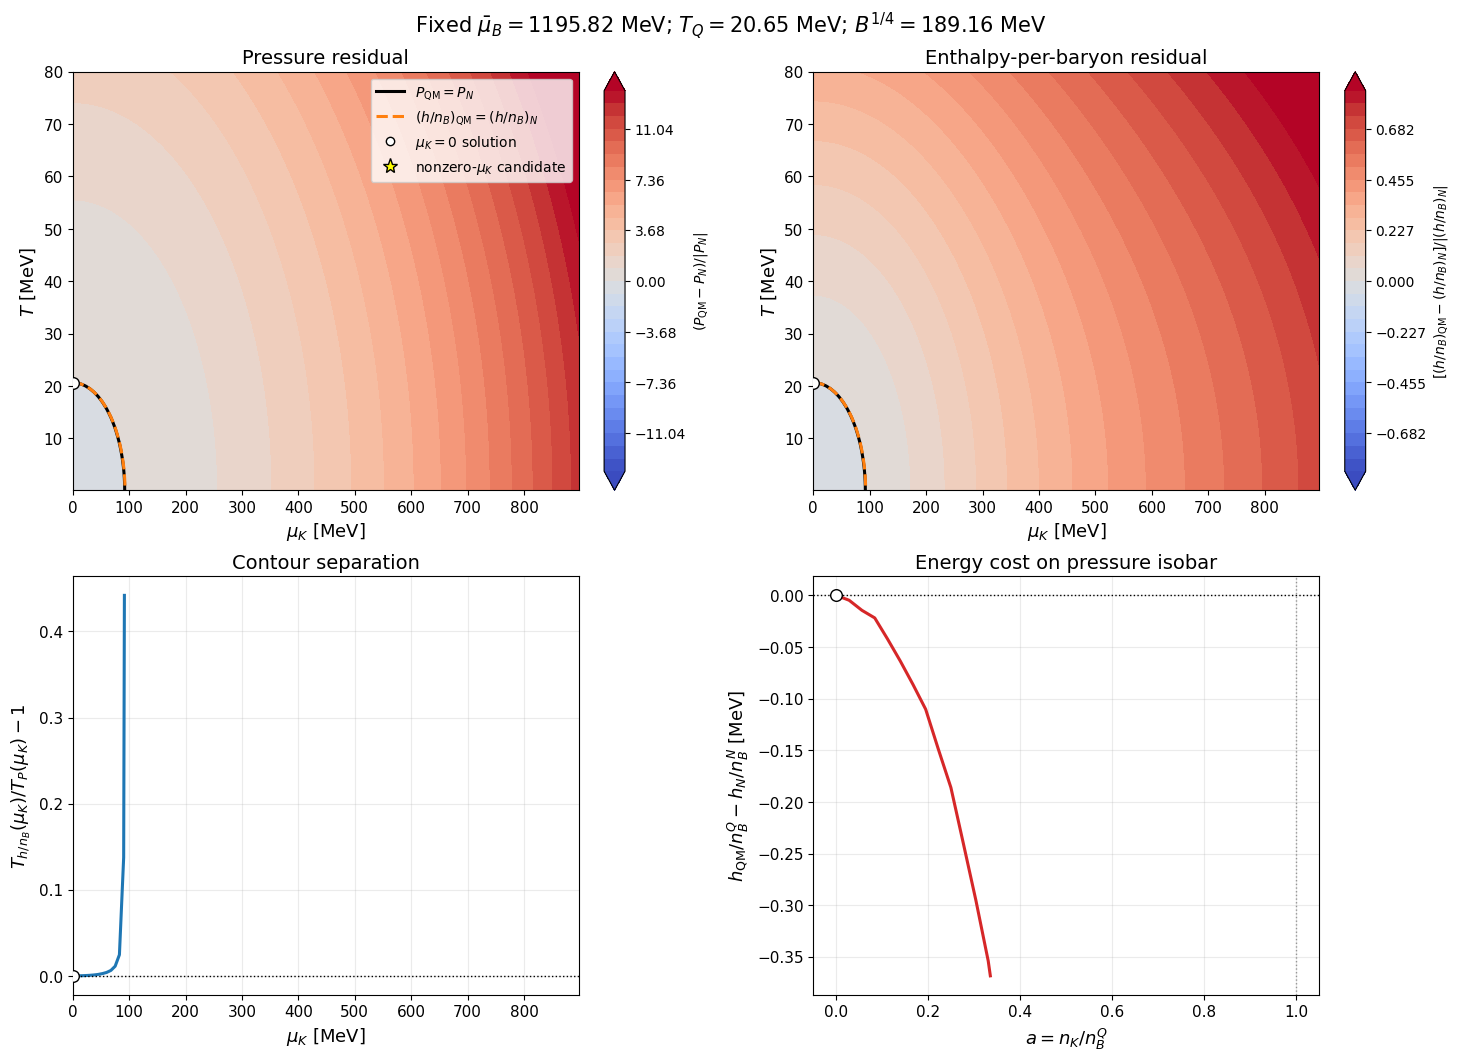

In [3]:
# FIXED_MUB_PRESSURE_ENTHALPY_VISUALIZATION
# Plot the fixed-muB diagnostic fields computed in the previous cell.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def _fixed_mub_symmetric_levels(values, n_levels=31, clip_percentile=98.0):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        return np.linspace(-1.0, 1.0, n_levels)
    vmax = float(np.nanpercentile(np.abs(finite), clip_percentile))
    vmax = max(vmax, 1.0e-8)
    return np.linspace(-vmax, vmax, n_levels)


def _fixed_mub_can_draw_zero(values):
    finite = np.asarray(values, dtype=float)
    finite = finite[np.isfinite(finite)]
    return bool(finite.size and np.nanmin(finite) <= 0.0 <= np.nanmax(finite))


def _fixed_mub_zero_contour_T_of_muK(field, prefer_T):
    T_of_muK = np.full(len(muK_values_fixed_mub), np.nan, dtype=float)
    for j in range(len(muK_values_fixed_mub)):
        values = np.asarray(field[:, j], dtype=float)
        finite = np.isfinite(values) & np.isfinite(T_values_fixed_mub)
        if np.count_nonzero(finite) < 2:
            continue
        T_col = T_values_fixed_mub[finite]
        v_col = values[finite]
        roots = []
        scale = max(float(np.nanmax(np.abs(v_col))), 1.0)
        exact = np.where(np.abs(v_col) <= 1.0e-10 * scale)[0]
        roots.extend(float(T_col[k]) for k in exact)
        changes = np.where(v_col[:-1] * v_col[1:] < 0.0)[0]
        for k in changes:
            T0, T1 = float(T_col[k]), float(T_col[k + 1])
            v0, v1 = float(v_col[k]), float(v_col[k + 1])
            if v1 == v0:
                continue
            roots.append(T0 - v0 * (T1 - T0) / (v1 - v0))
        if roots:
            T_of_muK[j] = min(roots, key=lambda value: abs(value - prefer_T))
    return T_of_muK


fixed_mub_T_pressure_isobar = _fixed_mub_zero_contour_T_of_muK(P_residual_fixed_mub, T_Q_fixed_mub)
fixed_mub_T_iso_h_over_nB = _fixed_mub_zero_contour_T_of_muK(h_residual_fixed_mub, T_Q_fixed_mub)
fixed_mub_contour_ratio = np.full_like(fixed_mub_T_pressure_isobar, np.nan, dtype=float)
fixed_mub_contour_fractional_separation = np.full_like(fixed_mub_T_pressure_isobar, np.nan, dtype=float)
_fixed_mub_contour_ratio_valid = (
    np.isfinite(fixed_mub_T_pressure_isobar)
    & np.isfinite(fixed_mub_T_iso_h_over_nB)
    & (fixed_mub_T_pressure_isobar > 0.0)
)
fixed_mub_contour_ratio[_fixed_mub_contour_ratio_valid] = (
    fixed_mub_T_iso_h_over_nB[_fixed_mub_contour_ratio_valid]
    / fixed_mub_T_pressure_isobar[_fixed_mub_contour_ratio_valid]
)
fixed_mub_contour_fractional_separation[_fixed_mub_contour_ratio_valid] = (
    fixed_mub_contour_ratio[_fixed_mub_contour_ratio_valid] - 1.0
)

fixed_mub_isobar_a_values = np.full_like(fixed_mub_T_pressure_isobar, np.nan, dtype=float)
fixed_mub_delta_h_over_nB_isobar = np.full_like(fixed_mub_T_pressure_isobar, np.nan, dtype=float)
for j, (muK_val, T_isobar) in enumerate(zip(muK_values_fixed_mub, fixed_mub_T_pressure_isobar)):
    if not np.isfinite(T_isobar):
        continue
    try:
        _, h_over_nB_Q, _, _, a_value = _fixed_mub_quark_quantities(float(muK_val), float(T_isobar))
    except Exception:
        continue
    fixed_mub_isobar_a_values[j] = a_value
    fixed_mub_delta_h_over_nB_isobar[j] = h_over_nB_Q - h_over_nB_N_fixed_mub

_fixed_mub_delta_valid = np.isfinite(fixed_mub_isobar_a_values) & np.isfinite(fixed_mub_delta_h_over_nB_isobar)
if np.any(_fixed_mub_contour_ratio_valid):
    max_sep = float(np.nanmax(np.abs(fixed_mub_contour_fractional_separation[_fixed_mub_contour_ratio_valid])))
    print(f'Max |T_h/T_P - 1| on matched zero-contour branches: {max_sep:.3e}')
else:
    print('No shared muK columns had both zero-contour branches, so the contour-ratio plot is empty.')

if np.any(_fixed_mub_delta_valid):
    delta_min = float(np.nanmin(fixed_mub_delta_h_over_nB_isobar[_fixed_mub_delta_valid]))
    delta_max = float(np.nanmax(fixed_mub_delta_h_over_nB_isobar[_fixed_mub_delta_valid]))
    a_max = float(np.nanmax(fixed_mub_isobar_a_values[_fixed_mub_delta_valid]))
    print(f'Along the pressure isobar: min/max Delta(h/nB) = {delta_min:.6g}, {delta_max:.6g} MeV; max a = {a_max:.6g}')
else:
    print('No pressure-isobar points were available for the Delta(h/nB) plot.')

fixed_mub_figsize_visual = (14.5, 10.5)
fig, axes = plt.subplots(2, 2, figsize=fixed_mub_figsize_visual, constrained_layout=True, facecolor='white')
axes = np.asarray(axes)
field_plot_specs = [
    (axes[0, 0], P_residual_fixed_mub, 'Pressure residual', r'$(P_{\rm QM}-P_N)/|P_N|$'),
    (axes[0, 1], h_residual_fixed_mub, 'Enthalpy-per-baryon residual', r'$[(h/n_B)_{\rm QM}-(h/n_B)_N]/|(h/n_B)_N|$'),
]

for ax, field, title, cbar_label in field_plot_specs:
    levels = _fixed_mub_symmetric_levels(field)
    cf = ax.contourf(MU_K_grid_fixed_mub, T_grid_fixed_mub, field, levels=levels, cmap=fixed_mub_cmap, extend='both')
    fig.colorbar(cf, ax=ax, label=cbar_label)

    if _fixed_mub_can_draw_zero(P_residual_fixed_mub):
        ax.contour(MU_K_grid_fixed_mub, T_grid_fixed_mub, P_residual_fixed_mub, levels=[0.0], colors='black', linewidths=fixed_mub_contour_lw, linestyles='solid')
    if _fixed_mub_can_draw_zero(h_residual_fixed_mub):
        ax.contour(MU_K_grid_fixed_mub, T_grid_fixed_mub, h_residual_fixed_mub, levels=[0.0], colors='#ff7f0e', linewidths=fixed_mub_contour_lw, linestyles='dashed')

    if len(fixed_mub_root_df):
        downstream = fixed_mub_root_df['branch'].to_numpy() == 'downstream'
        nonzero = ~downstream
        if np.any(downstream):
            ax.scatter(fixed_mub_root_df.loc[downstream, 'muK_MeV'], fixed_mub_root_df.loc[downstream, 'T_MeV'], s=70, marker='o', color='white', edgecolor='black', zorder=5)
        if np.any(nonzero):
            ax.scatter(fixed_mub_root_df.loc[nonzero, 'muK_MeV'], fixed_mub_root_df.loc[nonzero, 'T_MeV'], s=80, marker='*', color='yellow', edgecolor='black', zorder=6)
            for _, row in fixed_mub_root_df.loc[nonzero].iterrows():
                ax.annotate(fr'$a={row["a_Qstar"]:.3g}$', (row['muK_MeV'], row['T_MeV']), xytext=(5, 5), textcoords='offset points', fontsize=9)

    ax.set_title(title, fontsize=fixed_mub_title_fontsize)
    ax.set_xlabel(r'$\mu_K$ [MeV]', fontsize=fixed_mub_label_fontsize)
    ax.set_ylabel(r'$T$ [MeV]', fontsize=fixed_mub_label_fontsize)
    ax.tick_params(labelsize=fixed_mub_tick_fontsize)
    ax.set_xlim(0.0, float(muK_max_fixed_mub))
    ax.set_ylim(float(T_min_fixed_mub), float(T_max_fixed_mub))

ax = axes[1, 0]
if np.any(_fixed_mub_contour_ratio_valid):
    ax.plot(
        muK_values_fixed_mub[_fixed_mub_contour_ratio_valid],
        fixed_mub_contour_fractional_separation[_fixed_mub_contour_ratio_valid],
        color='#1f77b4',
        lw=2.2,
    )
    ax.scatter([0.0], [0.0], s=70, marker='o', color='white', edgecolor='black', zorder=5)
else:
    ax.text(0.5, 0.5, 'No shared zero-contour branch', ha='center', va='center', transform=ax.transAxes)
ax.axhline(0.0, color='black', lw=1.0, ls=':')
ax.set_title('Contour separation', fontsize=fixed_mub_title_fontsize)
ax.set_xlabel(r'$\mu_K$ [MeV]', fontsize=fixed_mub_label_fontsize)
ax.set_ylabel(r'$T_{h/n_B}(\mu_K)/T_P(\mu_K)-1$', fontsize=fixed_mub_label_fontsize)
ax.tick_params(labelsize=fixed_mub_tick_fontsize)
ax.set_xlim(0.0, float(muK_max_fixed_mub))
ax.grid(True, alpha=0.25)
ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))

ax = axes[1, 1]
if np.any(_fixed_mub_delta_valid):
    order = np.argsort(fixed_mub_isobar_a_values[_fixed_mub_delta_valid])
    a_plot = fixed_mub_isobar_a_values[_fixed_mub_delta_valid][order]
    delta_plot = fixed_mub_delta_h_over_nB_isobar[_fixed_mub_delta_valid][order]
    ax.plot(a_plot, delta_plot, color='#d62728', lw=2.2)
    ax.scatter([0.0], [0.0], s=70, marker='o', color='white', edgecolor='black', zorder=5)
else:
    ax.text(0.5, 0.5, 'No pressure-isobar branch', ha='center', va='center', transform=ax.transAxes)
ax.axhline(0.0, color='black', lw=1.0, ls=':')
ax.axvline(1.0, color='gray', lw=1.0, ls=':', alpha=0.8)
ax.set_title('Energy cost on pressure isobar', fontsize=fixed_mub_title_fontsize)
ax.set_xlabel(r'$a=n_K/n_B^Q$', fontsize=fixed_mub_label_fontsize)
ax.set_ylabel(r'$h_{\rm QM}/n_B^Q-h_N/n_B^N$ [MeV]', fontsize=fixed_mub_label_fontsize)
ax.tick_params(labelsize=fixed_mub_tick_fontsize)
ax.grid(True, alpha=0.25)
ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))

legend_handles = [
    Line2D([0], [0], color='black', lw=fixed_mub_contour_lw, ls='solid', label=r'$P_{\rm QM}=P_N$'),
    Line2D([0], [0], color='#ff7f0e', lw=fixed_mub_contour_lw, ls='dashed', label=r'$(h/n_B)_{\rm QM}=(h/n_B)_N$'),
    Line2D([0], [0], marker='o', color='white', markeredgecolor='black', lw=0, label=r'$\mu_K=0$ solution'),
    Line2D([0], [0], marker='*', color='yellow', markeredgecolor='black', lw=0, markersize=11, label=r'nonzero-$\mu_K$ candidate'),
]
axes[0, 0].legend(handles=legend_handles, loc='best', fontsize=fixed_mub_legend_fontsize)
fig.suptitle(
    fr'Fixed $\bar{{\mu}}_B={muB_bar_fixed_mub:.2f}$ MeV; $T_Q={T_Q_fixed_mub:.2f}$ MeV; $B^{{1/4}}={B14_fixed_mub:.2f}$ MeV',
    fontsize=fixed_mub_title_fontsize + 1,
)
plt.show()
